In [1]:
# yfinance is already in Colab, this just makes sure it is a recent version
%pip install -q --upgrade yfinance

In [2]:
# standard Python tools for file paths, dates, saving JSON and checking versions
from pathlib import Path
from datetime import date, datetime
import json
import platform
import warnings

# data handling, charts and the Yahoo Finance downloader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import yfinance as yf
from IPython.display import display
# clustering tools: Ward (scipy), K-means, scaling, PCA and the scores used to compare clusters
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# hide pandas 'this will change in a future version' notices so the outputs stay readable
warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
# ---- study settings (from the coursework brief) ----
START_DATE = "2021-01-01"
END_DATE = "2025-01-01"          # exclusive, so 31 Dec 2024 is the last possible day
BENCHMARK = "^GSPC"
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# ---- RFM rules ----
BASELINE_SESSIONS = 20           # sessions in the "normal volume" average
WINDOW_SESSIONS = 60             # sessions used for Frequency and Monetary
SPIKE_MULTIPLE = 2.0             # high volume day = volume above 2x the baseline

# ---- clustering ----
K_VALUES = range(2, 9)
SEED = 42
N_INIT = 25                      # number of K-means starts
MIN_CLUSTER_PCT = 0.05           # clusters under 5% of shares count as outlier groups
K_CHOICE = {}                    # optional manual pick, e.g. {"ward_activity": 3}

# ---- folders ----
DATA_DIR = Path("data")          # raw snapshot, not edited after it is saved
OUT_DIR = Path("outputs")        # tables and figures for the report
REFRESH_DATA = False             # True = download again even if a snapshot exists
# create the two folders if they are not there yet
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

In [4]:
# save each figure into the outputs folder so it can go in the report
def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


# record the library versions so the run can be repeated with the same setup
versions = {
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "yfinance": yf.__version__, "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
    "matplotlib": plt.matplotlib.__version__, "seaborn": sns.__version__,
}
print(" | ".join(f"{k} {v}" for k, v in versions.items()))

python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | yfinance 1.8.0 | scikit-learn 1.6.1 | scipy 1.16.3 | matplotlib 3.10.0 | seaborn 0.13.2


In [5]:
# 1.1 ticker list: read the saved copy if there is one, otherwise read it from Wikipedia
constituents_file = DATA_DIR / "sp500_constituents.csv"

if constituents_file.exists() and not REFRESH_DATA:
    constituents = pd.read_csv(constituents_file)
    print("Using the saved constituent list")
else:
    # read_html returns every table on the page, and the first one is the constituent list
    # (the User-Agent header is needed because Wikipedia blocks the default one)
    wiki_tables = pd.read_html(WIKI_URL, storage_options={"User-Agent": "Mozilla/5.0"})
    constituents = wiki_tables[0].copy()
    # Yahoo writes share classes with a dash, so BRK.B becomes BRK-B
    constituents["ticker"] = constituents["Symbol"].str.replace(".", "-", regex=False)
    # store the retrieval date next to the list, as the brief asks
    constituents["retrieved_on"] = date.today().isoformat()
    constituents.to_csv(constituents_file, index=False)
    print("Downloaded the constituent list from Wikipedia")

# the tickers used for the download, with a check that none appear twice
tickers = constituents["ticker"].tolist()
assert constituents["ticker"].is_unique, "duplicate tickers in the list"

print("Retrieval date:", constituents["retrieved_on"].iloc[0])
print("Tickers:", len(tickers))
print("First rows of the constituent list")
display(constituents[["Symbol", "ticker", "Security", "GICS Sector", "Date added"]].head())

Using the saved constituent list
Retrieval date: 2026-11-25
Tickers: 503
First rows of the constituent list


,Symbol,ticker,Security,GICS Sector,Date added
0,MMM,MMM,3M,Industrials,1957-03-04
1,AOS,AOS,A. O. Smith,Industrials,2017-07-26
2,ABT,ABT,Abbott Laboratories,Health Care,1957-03-04
3,ABBV,ABBV,AbbVie,Health Care,2012-12-31
4,ACN,ACN,Accenture,Information Technology,2011-07-06


In [6]:
import logging   # used to quieten yfinance during the retry below

# the five Yahoo columns we keep (our file name: Yahoo column name)
PRICE_FIELDS = {"close": "Close", "adj_close": "Adj Close", "volume": "Volume",
                "dividends": "Dividends", "splits": "Stock Splits"}
# all the files that make up a complete saved snapshot
snapshot_files = [DATA_DIR / f"{name}.csv" for name in PRICE_FIELDS]
snapshot_files += [DATA_DIR / "benchmark.csv", DATA_DIR / "provenance.json"]


# download daily data for a list of tickers and return one table (dates x tickers) per field
# auto_adjust=False keeps Close and Adj Close separate, actions=True adds dividends and splits
def download_shares(symbols):
    raw = yf.download(symbols, start=START_DATE, end=END_DATE, auto_adjust=False,
                      actions=True, progress=False, threads=True)
    # yfinance returns one wide table with two header levels (field, ticker)
    available = raw.columns.get_level_values(0)
    frames = {}
    for name, field in PRICE_FIELDS.items():
        if field in available:
            frames[name] = raw[field].reindex(columns=symbols)
        else:
            # tickers that fail come back without Dividends / Stock Splits columns
            frames[name] = pd.DataFrame(np.nan, index=raw.index, columns=symbols)
    return frames


# download every run so the yfinance errors for the failed tickers are always shown
prices = download_shares(tickers)

# Yahoo sometimes rate limits a few symbols, so the empty ones get one more try
empty = [t for t in tickers if prices["close"][t].isna().all()]
if empty:
    # the first download already printed the errors for these tickers, so yfinance
    # messages are muted during the retry to stop the same errors printing twice
    yf_logger = logging.getLogger("yfinance")
    old_level = yf_logger.level
    yf_logger.setLevel(logging.CRITICAL)
    try:
        retry = download_shares(empty)
    finally:
        yf_logger.setLevel(old_level)
    for name in PRICE_FIELDS:
        prices[name] = prices[name].combine_first(retry[name])[tickers]

# benchmark: the S&P 500 index itself (^GSPC), same dates
bench_raw = yf.download(BENCHMARK, start=START_DATE, end=END_DATE,
                        auto_adjust=False, progress=False)

# the snapshot is only written if there is no complete one yet (or REFRESH_DATA is True),
# so the analysis below always reads the same saved data
if not all(f.exists() for f in snapshot_files) or REFRESH_DATA:
    # save each field as its own CSV so later cells always read the same data
    for name, frame in prices.items():
        if name in ("dividends", "splits"):
            frame = frame.fillna(0)      # no row just means no corporate action that day
        frame.to_csv(DATA_DIR / f"{name}.csv")

    pd.DataFrame({
        "Close": bench_raw["Close"].squeeze("columns"),
        "Adj Close": bench_raw["Adj Close"].squeeze("columns"),
    }).to_csv(DATA_DIR / "benchmark.csv")

    # provenance record: where the data came from, when, and with which settings
    provenance = {
        "constituent_source": WIKI_URL,
        "constituents_retrieved_on": constituents["retrieved_on"].iloc[0],
        "price_source": "Yahoo Finance via yfinance (yf.download, interval 1d, auto_adjust=False, actions=True)",
        "prices_downloaded_on": date.today().isoformat(),
        "start_inclusive": START_DATE,
        "end_exclusive": END_DATE,
        "benchmark": BENCHMARK,
        "tickers_requested": len(tickers),
        "failed_downloads": [t for t in tickers if prices["close"][t].isna().all()],
        "library_versions": versions,
    }
    (DATA_DIR / "provenance.json").write_text(json.dumps(provenance, indent=2))

ERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'VYLR', 'FDXF', 'HONA', 'Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


In [7]:
# read one saved CSV back in, with the dates as the row index
def read_wide(name):
    return pd.read_csv(DATA_DIR / f"{name}.csv", index_col=0, parse_dates=True)


# every cell from here on uses these saved files, not the live download
close = read_wide("close")
adj_close = read_wide("adj_close")
volume = read_wide("volume")
dividends = read_wide("dividends")
splits = read_wide("splits")
benchmark = read_wide("benchmark")
provenance = json.loads((DATA_DIR / "provenance.json").read_text())

# one table with the evidence for 1.1: dates, counts, study period and benchmark
snapshot_summary = pd.DataFrame({"value": {
    "Constituent list retrieved on": provenance["constituents_retrieved_on"],
    "Prices downloaded on": provenance["prices_downloaded_on"],
    "Tickers requested": len(tickers),
    "Tickers with no data returned": len(provenance["failed_downloads"]),
    "Trading days in share data": len(close),
    "First / last share date": f"{close.index.min():%Y-%m-%d} / {close.index.max():%Y-%m-%d}",
    "Benchmark trading days": len(benchmark),
    "Benchmark": BENCHMARK,
    "Last date is before the exclusive end date": bool(close.index.max() < pd.Timestamp(END_DATE)),
}})
print("Saved snapshot used for the analysis")
display(snapshot_summary)
print("No data returned for:", provenance["failed_downloads"])

Saved snapshot used for the analysis


,value
Constituent list retrieved on,2026-11-25
Prices downloaded on,2026-11-25
Tickers requested,503
Tickers with no data returned,5
Trading days in share data,1005
First / last share date,2021-01-04 / 2024-12-31
Benchmark trading days,1005
Benchmark,^GSPC
Last date is before the exclusive end date,True


No data returned for: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [8]:
# line the shares up on the benchmark trading calendar (no filling)
trading_days = benchmark.index
# share dates that are not benchmark trading days get dropped (they are counted below)
extra_share_days = close.index.difference(trading_days)
# reindex puts every share on the same calendar; missing days stay empty (NaN) and are never filled
close, adj_close, volume = (f.reindex(trading_days) for f in (close, adj_close, volume))
# for dividends and splits an empty day just means no event, so 0 is correct here
dividends = dividends.reindex(trading_days).fillna(0)
splits = splits.reindex(trading_days).fillna(0)
bench_close, bench_adj = benchmark["Close"], benchmark["Adj Close"]

# 1.2 checks on the whole dataset: duplicate dates, date order, missing or bad benchmark prices
dataset_checks = pd.DataFrame({"result": {
    "Duplicate dates in benchmark": int(trading_days.duplicated().sum()),
    "Duplicate dates in share data": int(read_wide("close").index.duplicated().sum()),
    "Dates in ascending order": bool(trading_days.is_monotonic_increasing),
    "Share dates not on the benchmark calendar (dropped)": len(extra_share_days),
    "Missing benchmark prices": int(benchmark.isna().sum().sum()),
    "Non-positive benchmark prices": int((benchmark <= 0).sum().sum()),
    "Benchmark Adj Close equal to Close (checked, not assumed)": bool(np.allclose(bench_adj, bench_close)),
}})
print("Dataset level checks")
display(dataset_checks)

# stop the notebook if the calendar or the benchmark is broken
assert trading_days.is_unique and trading_days.is_monotonic_increasing
assert benchmark.notna().all().all() and (benchmark > 0).all().all()

Dataset level checks


,result
Duplicate dates in benchmark,0
Duplicate dates in share data,0
Dates in ascending order,True
Share dates not on the benchmark calendar (dropped),0
Missing benchmark prices,0
Non-positive benchmark prices,0
"Benchmark Adj Close equal to Close (checked, not assumed)",True


In [9]:
# 1.2 checks for each share: count the problem days for every ticker
n_days = len(trading_days)
# a day is complete only if Close, Adj Close and Volume are all there
complete_row = close.notna() & adj_close.notna() & volume.notna()

checks = pd.DataFrame(index=pd.Index(tickers, name="ticker"))
checks["first_date"] = close.apply(lambda s: s.first_valid_index())
checks["valid_days"] = complete_row.sum()
checks["missing_days"] = n_days - checks["valid_days"]
checks["nonpositive_days"] = ((close <= 0) | (adj_close <= 0)).sum()
checks["zero_volume_days"] = (volume == 0).sum()
checks["negative_volume_days"] = (volume < 0).sum()
checks["split_events"] = (splits != 0).sum()
checks["dividend_events"] = (dividends > 0).sum()


# apply the rules in order and return the first one the share breaks
def exclusion_reason(row):
    """Return (reason, detail) for the first rule a share breaks, or (None, None)."""
    if row["valid_days"] == 0:
        return "No data", "nothing returned for 2021 to 2024"
    if row["missing_days"] > 0:
        return ("Unequal history",
                f"first price {row['first_date']:%Y-%m-%d}, {row['missing_days']} of {n_days} days missing")
    if row["nonpositive_days"] > 0:
        return "Non-positive price", f"{row['nonpositive_days']} days at or below zero"
    if row["zero_volume_days"] > 0 or row["negative_volume_days"] > 0:
        bad = volume.index[volume[row.name] <= 0]
        return ("Volume error",
                f"{len(bad)} days with zero or negative volume ({bad[0]:%Y-%m-%d} to {bad[-1]:%Y-%m-%d})")
    return None, None


# run the rules on every share; shares with no reason are kept
checks[["reason", "detail"]] = checks.apply(exclusion_reason, axis=1, result_type="expand")
kept = checks.index[checks["reason"].isna()].tolist()

# exclusion log: each excluded share with its name, sector, reason and detail
sector_lookup = constituents.set_index("ticker")[["Security", "GICS Sector"]]
exclusion_log = (checks.loc[checks["reason"].notna(), ["reason", "detail"]]
                 .join(sector_lookup)
                 .assign(stage="1.2 validation"))

print(f"Tickers on the list: {len(tickers)} | excluded: {len(exclusion_log)} | kept: {len(kept)}")
print("Exclusions by reason")
display(exclusion_log["reason"].value_counts().rename("shares").to_frame())
print("Exclusion log (validation stage)")
display(exclusion_log[["Security", "GICS Sector", "reason", "detail"]])

Tickers on the list: 503 | excluded: 17 | kept: 486
Exclusions by reason


,shares
reason,
Unequal history,10
No data,5
Volume error,2


Exclusion log (validation stage)


,Security,GICS Sector,reason,detail
ticker,,,,
APP,AppLovin,Communication Services,Unequal history,"first price 2021-04-15, 70 of 1005 days missing"
COIN,Coinbase,Financials,Unequal history,"first price 2021-04-14, 69 of 1005 days missing"
CEG,Constellation Energy,Utilities,Unequal history,"first price 2022-01-19, 263 of 1005 days missing"
EXE,Expand Energy,Energy,Unequal history,"first price 2021-02-10, 26 of 1005 days missing"
FDXF,FedEx Freight,Industrials,No data,nothing returned for 2021 to 2024
FERG,Ferguson Enterprises,Industrials,Volume error,27 days with zero or negative volume (2021-01-...
GEHC,GE HealthCare,Health Care,Unequal history,"first price 2022-12-15, 492 of 1005 days missing"
GEV,GE Vernova,Industrials,Unequal history,"first price 2024-03-27, 812 of 1005 days missing"
HONA,Honeywell Aerospace,Industrials,No data,nothing returned for 2021 to 2024


In [10]:
# split check: compare each split day with the 5 trading days before and after it
traded_value = close[kept] * volume[kept]
split_rows = []

for ticker in kept:
    for split_day in splits.index[splits[ticker] != 0]:
        pos = trading_days.get_loc(split_day)
        if pos < 5:
            continue
        # the 5 sessions before the split, and the 5 sessions from the split day on
        before, after = trading_days[pos - 5:pos], trading_days[pos:pos + 5]
        split_rows.append({
            "ticker": ticker,
            "split_date": split_day.date(),
            "ratio": splits.at[split_day, ticker],
            "close_change_on_day": close.at[split_day, ticker] / close[ticker].iloc[pos - 1] - 1,
            "value_ratio_after_before": traded_value[ticker].loc[after].median()
                                        / traded_value[ticker].loc[before].median(),
        })

split_check = pd.DataFrame(split_rows, columns=["ticker", "split_date", "ratio",
                                                "close_change_on_day", "value_ratio_after_before"])
# a split-adjusted Close should not jump on the split day (less than a 25% move)
# a big traded value jump is only flagged for a manual look, it is not treated as an error
split_check["close_continuous"] = split_check["close_change_on_day"].abs() < 0.25
split_check["value_jump_to_check"] = ~split_check["value_ratio_after_before"].between(0.5, 2)
print(f"Split days for kept shares ({len(split_check)} events)")
display(split_check)

print("Close continuous across every split:", bool(split_check["close_continuous"].all()))
print("Traded value jumps worth a look:", split_check.loc[split_check["value_jump_to_check"], "ticker"].tolist() or "none")

# dividend check: Adj Close return against (Close today + dividend) / Close yesterday - 1
adj_return = adj_close[kept].pct_change(fill_method=None)
cash_return = (close[kept] + dividends[kept]) / close[kept].shift(1) - 1
# size of the difference between the two daily returns, for every share and day
gap = (adj_return - cash_return).abs()

# summary of the dividend check, plus a count of very large daily moves
dividend_check = pd.DataFrame({"value": {
    "Dividend events (kept shares)": int((dividends[kept] > 0).sum().sum()),
    "Share-days compared": int(gap.notna().sum().sum()),
    "Largest gap between the two returns": f"{gap.max().max():.4%}",
    "Share-days with a gap above 0.5%": int((gap > 0.005).sum().sum()),
    "Shares with at least one such day": int((gap > 0.005).any().sum()),
    "Daily moves above 40% (Adj Close)": int((adj_return.abs() > 0.40).sum().sum()),
}})
print("Adjusted price consistency")
display(dividend_check)
# the five shares with the biggest gap, so they can be looked at by hand
worst = gap.max().sort_values(ascending=False).head(5).rename("largest_gap").to_frame()
print("Shares with the largest gap (for inspection)")
display(worst)

Split days for kept shares (61 events)


,ticker,split_date,ratio,close_change_on_day,value_ratio_after_before,close_continuous,value_jump_to_check
0,MMM,2024-04-01,1.196,0.060129,1.188733,True,False
1,GOOGL,2022-07-18,20.000,-0.024580,1.018007,True,False
2,GOOG,2022-07-18,20.000,-0.025335,0.984882,True,False
3,AMZN,2022-06-06,20.000,0.019943,0.758135,True,False
4,APH,2021-03-05,2.000,0.025316,0.967799,True,False
...,...,...,...,...,...,...,...
56,WRB,2022-03-24,1.500,0.000613,1.164213,True,False
57,WRB,2024-07-11,1.500,-0.015007,1.381793,True,False
58,WMT,2024-02-26,3.000,0.018455,0.476861,True,True
59,WSM,2024-07-09,2.000,-0.002595,0.968226,True,False


Close continuous across every split: True
Traded value jumps worth a look: ['COO', 'GE', 'GE', 'SMCI', 'WMT']
Adjusted price consistency


,value
Dividend events (kept shares),6024
Share-days compared,487944
Largest gap between the two returns,0.5444%
Share-days with a gap above 0.5%,1
Shares with at least one such day,1
Daily moves above 40% (Adj Close),8


Shares with the largest gap (for inspection)


,largest_gap
TKO,0.005444
TGT,0.001537
WY,0.001063
AES,0.001033
T,0.000900


In [11]:
# survivorship evidence: kept shares that only joined the index after the start date
date_added = pd.to_datetime(constituents.set_index("ticker").loc[kept, "Date added"], errors="coerce")
# True for shares that were added to the index after the study started
joined_late = date_added > pd.Timestamp(START_DATE)
print(f"{joined_late.sum()} of {len(kept)} kept shares ({joined_late.mean():.1%}) were added to the "
      f"S&P 500 after {START_DATE}.")
print("They are in the sample because they are members today, not because they were members in 2021.")

# save the checks and logs for the report
checks.to_csv(OUT_DIR / "validation_checks.csv")
exclusion_log.to_csv(OUT_DIR / "exclusion_log_validation.csv")
split_check.to_csv(OUT_DIR / "split_checks.csv", index=False)

72 of 486 kept shares (14.8%) were added to the S&P 500 after 2021-01-01.
They are in the sample because they are members today, not because they were members in 2021.


In [12]:
# 1.3 weekly prices: group the days into Friday-ending weeks and take the last price of each week
weekly_prices = adj_close[kept].resample("W-FRI").last()
bench_weekly = bench_adj.resample("W-FRI").last()
# number of trading days in each week (used to count holiday-shortened weeks)
sessions_per_week = adj_close[kept].iloc[:, 0].resample("W-FRI").count()

# a week is complete only if its whole Monday to Friday span is inside the study period
week_end = weekly_prices.index
week_start = week_end - pd.Timedelta(days=4)
complete_week = (week_start >= pd.Timestamp(START_DATE)) & (week_end < pd.Timestamp(END_DATE))

# remember which weeks are dropped, then keep only the complete weeks
dropped_weeks = [d.strftime("%Y-%m-%d") for d in week_end[~complete_week]]
weekly_prices = weekly_prices[complete_week]
bench_weekly = bench_weekly[complete_week]
sessions_per_week = sessions_per_week[complete_week]

# safety checks: no gaps, no missing prices, so no return can span two weeks
assert (weekly_prices.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all()
assert weekly_prices.notna().all().all() and bench_weekly.notna().all()
assert weekly_prices.index.equals(bench_weekly.index)

# weekly return = this week's price / last week's price - 1 (the first week has no previous week)
weekly_returns = weekly_prices.pct_change(fill_method=None).iloc[1:]
bench_returns = bench_weekly.pct_change(fill_method=None).iloc[1:]
assert weekly_returns.index.equals(bench_returns.index)

# evidence that the shares and the benchmark use exactly the same weeks
week_summary = pd.DataFrame({"value": {
    "Week labels after resampling": int(complete_week.size),
    "Complete weeks kept": int(complete_week.sum()),
    "Incomplete weeks removed": ", ".join(dropped_weeks) or "none",
    "Weekly returns per share (aligned with benchmark)": len(weekly_returns),
    "First / last return week": f"{weekly_returns.index[0]:%Y-%m-%d} / {weekly_returns.index[-1]:%Y-%m-%d}",
    "Holiday shortened weeks kept": int((sessions_per_week < 5).sum()),
    "Missing weekly returns": int(weekly_returns.isna().sum().sum()),
}})
print("Weekly alignment")
display(week_summary)
weekly_returns.to_csv(OUT_DIR / "weekly_returns.csv")

Weekly alignment


,value
Week labels after resampling,209
Complete weeks kept,208
Incomplete weeks removed,2025-01-03
Weekly returns per share (aligned with benchmark),207
First / last return week,2021-01-15 / 2024-12-27
Holiday shortened weeks kept,37
Missing weekly returns,0


In [13]:
# 1.3.1 return feature: the plain (arithmetic) average of each share's weekly returns
mean_weekly_return = weekly_returns.mean().rename("mean_weekly_return")
weekly_obs = weekly_returns.count().rename("weekly_obs")

# summary statistics across all kept shares, shown in %
summary = (mean_weekly_return * 100).describe().to_frame("mean weekly return (%)").T
print("Mean weekly return across kept shares (in %)")
display(summary)
print("Weekly observations per share: min", weekly_obs.min(), "| max", weekly_obs.max())

Mean weekly return across kept shares (in %)


,count,mean,std,min,25%,50%,75%,max
mean weekly return (%),486.0,0.285717,0.265161,-0.446809,0.118153,0.261893,0.420732,1.777248


Weekly observations per share: min 207 | max 207


In [14]:
# independent check on one share, straight from the daily prices
example = "AAPL" if "AAPL" in kept else kept[0]
daily = adj_close[example]

# take two weeks and work out the return by hand from the daily prices
week_a, week_b = weekly_returns.index[9], weekly_returns.index[10]
price_a = daily.loc[week_a - pd.Timedelta(days=6):week_a].iloc[-1]   # last trading price in week A
price_b = daily.loc[week_b - pd.Timedelta(days=6):week_b].iloc[-1]
manual_return = price_b / price_a - 1

# the compound (geometric) weekly return, to show it is lower than the arithmetic mean
geometric = (1 + weekly_returns[example]).prod() ** (1 / len(weekly_returns)) - 1
# the same mean using Close (no dividends), to show the effect of using Adj Close
close_based = close[example].resample("W-FRI").last()[complete_week].pct_change(fill_method=None).iloc[1:].mean()

check = pd.DataFrame({"value": {
    f"Manual return for week ending {week_b:%Y-%m-%d}": manual_return,
    "Return in the weekly table": weekly_returns.at[week_b, example],
    "Arithmetic mean (feature used)": mean_weekly_return[example],
    "Manual mean (sum / count)": weekly_returns[example].sum() / weekly_obs[example],
    "Geometric (compound) weekly return": geometric,
    "Mean using Close instead of Adj Close": close_based,
}})
print(f"Worked check of weekly returns for {example}")
display(check)
# stop if the hand calculation does not match the table
assert np.isclose(manual_return, weekly_returns.at[week_b, example])

Worked check of weekly returns for AAPL


,value
Manual return for week ending 2021-03-26,0.010168
Return in the weekly table,0.010168
Arithmetic mean (feature used),0.003930
Manual mean (sum / count),0.003930
Geometric (compound) weekly return,0.003304
Mean using Close instead of Adj Close,0.003822


In [15]:
# 1.3.2 beta = cov(share, market) / var(market), both with n - 1, on matched weeks
# it also returns the number of weeks used, R squared and the standard error of beta
def weekly_beta(share_returns, market_returns):
    # keep only the weeks where both the share and the market have a return
    pair = pd.concat([share_returns, market_returns], axis=1, join="inner").dropna()
    share, market = pair.iloc[:, 0], pair.iloc[:, 1]
    n = len(pair)
    beta = share.cov(market) / market.var()
    rho = share.corr(market)
    # standard error of the beta estimate (how precise it is)
    std_error = np.sqrt(share.var() * (1 - rho ** 2) / ((n - 2) * market.var()))
    return beta, n, rho ** 2, std_error


# run the beta function for every kept share and put the results in one table
beta_rows = [(t, *weekly_beta(weekly_returns[t], bench_returns)) for t in kept]
beta_table = pd.DataFrame(beta_rows, columns=["ticker", "weekly_beta", "aligned_weeks", "r_squared", "beta_se"])
beta_table = beta_table.set_index("ticker")

print("Weekly beta, fit and precision across kept shares")
display(beta_table.describe().T)
print("Aligned weekly observations per share: min", beta_table["aligned_weeks"].min(),
      "| max", beta_table["aligned_weeks"].max())

Weekly beta, fit and precision across kept shares


,count,mean,std,min,25%,50%,75%,max
weekly_beta,486.0,0.973695,0.407339,0.055452,0.666599,0.950610,1.179538,3.778560
aligned_weeks,486.0,207.000000,0.000000,207.000000,207.000000,207.000000,207.000000,207.000000
r_squared,486.0,0.279821,0.131159,0.002231,0.171793,0.283746,0.379825,0.638705
beta_se,486.0,0.112362,0.041412,0.056824,0.086010,0.100675,0.127341,0.436230


Aligned weekly observations per share: min 207 | max 207


In [16]:
# cross-check beta for the example share in two other ways
x, y = bench_returns.to_numpy(), weekly_returns[example].to_numpy()
cov_matrix = np.cov(y, x)                     # numpy, n - 1
ols_slope = np.polyfit(x, y, 1)[0]            # least squares slope

# all three methods should give the same number
beta_check = pd.DataFrame({"beta": {
    "Function above": beta_table.at[example, "weekly_beta"],
    "numpy covariance matrix": cov_matrix[0, 1] / cov_matrix[1, 1],
    "Least squares slope": ols_slope,
}})
print(f"Beta check for {example}")
display(beta_check)
assert np.allclose(beta_check["beta"], beta_check["beta"].iloc[0])

beta_table.to_csv(OUT_DIR / "weekly_beta.csv")

Beta check for AAPL


,beta
Function above,1.174835
numpy covariance matrix,1.174835
Least squares slope,1.174835


In [17]:
# 1.4 high volume day rule: volume > 2 x the mean of the previous 20 sessions
# shift(1) moves the data down one day, so a day's own volume is not in its baseline
def find_spikes(vol):
    """Flag high volume days. Works on one share (Series) or many (DataFrame)."""
    baseline = vol.shift(1).rolling(BASELINE_SESSIONS, min_periods=BASELINE_SESSIONS).mean()
    threshold = SPIKE_MULTIPLE * baseline
    return vol > threshold, baseline, threshold     # NaN threshold -> not a spike


# Recency: calendar days from the last high volume day to the observation date
# if a share never had one, Recency stays missing (NaN), it is not set to 0
def days_since_last_spike(spike_flags, obs_date):
    hits = spike_flags.index[spike_flags.to_numpy()]
    if len(hits) == 0:
        return pd.NaT, np.nan
    return hits[-1], float((obs_date - hits[-1]).days)


# observation date = last day with complete data for every kept share and the benchmark
rfm_volume, rfm_close = volume[kept], close[kept]
complete_day = rfm_volume.notna().all(axis=1) & rfm_close.notna().all(axis=1) & bench_close.notna()
obs_date = complete_day[complete_day].index.max()

# only use data up to the observation date, then flag the high volume days for every share
rfm_volume, rfm_close = rfm_volume.loc[:obs_date], rfm_close.loc[:obs_date]
spikes, baseline, threshold = find_spikes(rfm_volume)

# the last 60 sessions ending on the observation date (used for F and M)
window = rfm_volume.index[-WINDOW_SESSIONS:]
# check the window is right and every day in it has a full 20 session baseline
assert window[-1] == obs_date and len(window) == WINDOW_SESSIONS
assert threshold.loc[window].notna().all().all(), "a 20 session baseline is missing inside the window"

# work out R, F and M for each share
# F = number of high volume days in the window, M = sum of Close x Volume in the window
rfm_rows = []
for t in kept:
    last_spike, recency = days_since_last_spike(spikes[t], obs_date)
    rfm_rows.append({
        "ticker": t,
        "last_spike": last_spike,
        "recency": recency,
        "frequency": int(spikes.loc[window, t].sum()),
        "monetary": float((rfm_close.loc[window, t] * rfm_volume.loc[window, t]).sum()),
        "valid_sessions": int(rfm_volume[t].notna().sum()),
    })
rfm = pd.DataFrame(rfm_rows).set_index("ticker")

# summary of the RFM step, including the no-event and R = 0 cases
rfm_summary = pd.DataFrame({"value": {
    "Observation date": f"{obs_date:%Y-%m-%d}",
    "60 session window": f"{window[0]:%Y-%m-%d} to {window[-1]:%Y-%m-%d}",
    "First day with a full 20 session baseline": f"{threshold.dropna(how='all').index[0]:%Y-%m-%d}",
    "Shares with at least 80 valid sessions": int((rfm["valid_sessions"] >= 80).sum()),
    "High volume days flagged (all shares, whole period)": int(spikes.sum().sum()),
    "Shares with no high volume day (R missing)": int(rfm["recency"].isna().sum()),
    "Shares with a high volume day on the observation date (R = 0)": int((rfm["recency"] == 0).sum()),
    "Most common Recency (days) and share of shares":
        f"{rfm['recency'].mode().iloc[0]:.0f} ({(rfm['recency'] == rfm['recency'].mode().iloc[0]).mean():.0%})",
}})
print("RFM calculation summary")
display(rfm_summary)
# every share needs at least 80 sessions (20 for the baseline + 60 for the window)
assert (rfm["valid_sessions"] >= BASELINE_SESSIONS + WINDOW_SESSIONS).all()

# list every high volume day (date, ticker, volume, baseline, threshold) and save it
rows, cols = np.where(spikes.to_numpy())
spike_log = pd.DataFrame({
    "date": spikes.index[rows], "ticker": spikes.columns[cols],
    "volume": rfm_volume.to_numpy()[rows, cols],
    "baseline_20": baseline.to_numpy()[rows, cols],
    "threshold": threshold.to_numpy()[rows, cols],
})
spike_log.to_csv(OUT_DIR / "high_volume_days.csv", index=False)
rfm.to_csv(OUT_DIR / "rfm_features.csv")

RFM calculation summary


,value
Observation date,2024-12-31
60 session window,2024-10-07 to 2024-12-31
First day with a full 20 session baseline,2021-02-02
Shares with at least 80 valid sessions,486
"High volume days flagged (all shares, whole period)",18280
Shares with no high volume day (R missing),0
Shares with a high volume day on the observation date (R = 0),0
Most common Recency (days) and share of shares,11 (73%)


In [18]:
# makes a small test series: 20 days at 1 million shares, then one test day
def flat_then(value, days=20, level=1_000_000):
    idx = pd.bdate_range("2024-08-01", periods=days + 1)
    return pd.Series([level] * days + [value], index=idx, dtype=float)


# examples from the brief: 2.5m qualifies, 1.8m does not, exactly 2.0m does not (must be strictly greater)
tests = []
for vol, expected in [(2_500_000, True), (1_800_000, False), (2_000_000, False)]:
    flag = find_spikes(flat_then(vol))[0].iloc[-1]
    tests.append((f"Baseline 1.0m, volume {vol / 1e6:.1f}m qualifies?", expected, bool(flag)))

# Recency example from the brief: 15 Sep to 20 Sep is 5 calendar days
tests.append(("Recency for an event on 15 Sep, observed 20 Sep", 5,
              (pd.Timestamp("2024-09-20") - pd.Timestamp("2024-09-15")).days))

# edge case: a spike on the observation date itself gives R = 0
series = flat_then(3_000_000)
flags = find_spikes(series)[0]
tests.append(("Event on the observation date gives R = 0", 0.0,
              days_since_last_spike(flags, series.index[-1])[1]))

# edge case: no spike at all gives a missing Recency
flags = find_spikes(flat_then(1_000_000))[0]
tests.append(("No event gives a missing R (not 0)", "missing",
              "missing" if np.isnan(days_since_last_spike(flags, flags.index[-1])[1]) else "value"))

# the baseline for the 3m day should be 1m, which shows the day is not in its own average
tests.append(("Tested day is left out of its own baseline", 1_000_000.0,
              find_spikes(flat_then(3_000_000))[1].iloc[-1]))

# no look-ahead: removing all later data must not change the threshold on that day
cut_day = rfm_volume.index[500]
early = find_spikes(rfm_volume[example].loc[:cut_day])[2].iloc[-1]
tests.append(("No look-ahead: threshold same with later data removed", True,
              bool(np.isclose(early, threshold.at[cut_day, example]))))

# the first 20 sessions have no full baseline, so no spike can be flagged there
tests.append(("No event possible before 20 sessions of history", False,
              bool(spikes.iloc[:BASELINE_SESSIONS].any().any())))

# compare expected with actual results and stop the notebook if any check fails
rule_tests = pd.DataFrame(tests, columns=["check", "expected", "result"])
rule_tests["pass"] = rule_tests["expected"].astype(str) == rule_tests["result"].astype(str)
print("RFM rule checks")
display(rule_tests)
assert rule_tests["pass"].all()

RFM rule checks


,check,expected,result,pass
0,"Baseline 1.0m, volume 2.5m qualifies?",True,True,True
1,"Baseline 1.0m, volume 1.8m qualifies?",False,False,True
2,"Baseline 1.0m, volume 2.0m qualifies?",False,False,True
3,"Recency for an event on 15 Sep, observed 20 Sep",5,5,True
4,Event on the observation date gives R = 0,0.0,0.0,True
5,No event gives a missing R (not 0),missing,missing,True
6,Tested day is left out of its own baseline,1000000.0,1000000.0,True
7,No look-ahead: threshold same with later data ...,True,True,True
8,No event possible before 20 sessions of history,False,False,True


In [19]:
# worked example: daily volume, baseline, threshold and spike flag for the example share
ex = pd.DataFrame({
    "close": rfm_close[example], "volume": rfm_volume[example],
    "baseline_20": baseline[example], "threshold": threshold[example], "spike": spikes[example],
})
# how many times bigger than normal each day's volume was, and that day's traded value
ex["volume_vs_baseline"] = ex["volume"] / ex["baseline_20"]
ex["traded_value"] = ex["close"] * ex["volume"]
ex_window = ex.loc[window]

# R, F and M worked out by hand for this share
last_spike = ex.index[ex["spike"]][-1]
recency_hand = (obs_date - last_spike).days
frequency_hand = int(ex_window["spike"].sum())
monetary_hand = ex_window["traded_value"].sum()

print(f"{example}: latest high volume days")
display(ex[ex["spike"]].tail(6)[["close", "volume", "baseline_20", "threshold", "volume_vs_baseline"]])
print("First three days of the 60 session window")
display(ex_window[["close", "volume", "traded_value"]].head(3))

# the hand calculation next to the value in the feature table
worked = pd.DataFrame({
    "worked by hand": [f"{obs_date:%d %b %Y} - {last_spike:%d %b %Y} = {recency_hand} days",
                       f"{frequency_hand} high volume days in {window[0]:%d %b} to {window[-1]:%d %b %Y}",
                       f"sum of 60 x (Close x Volume) = ${monetary_hand / 1e9:,.2f} bn"],
    "feature table": [f"{rfm.at[example, 'recency']:.0f} days", f"{rfm.at[example, 'frequency']} days",
                      f"${rfm.at[example, 'monetary'] / 1e9:,.2f} bn"],
}, index=["Recency", "Frequency", "Monetary"])
print(f"Worked RFM example for {example} (observation date {obs_date:%Y-%m-%d})")
display(worked)
# stop if the hand calculation and the table do not agree
assert recency_hand == rfm.at[example, "recency"] and frequency_hand == rfm.at[example, "frequency"]
assert np.isclose(monetary_hand, rfm.at[example, "monetary"])

AAPL: latest high volume days


,close,volume,baseline_20,threshold,volume_vs_baseline
Date,,,,,
2024-06-12,213.070007,198134300,58567360.0,117134720.0,3.383016
2024-06-21,207.490005,241805100,74685930.0,149371860.0,3.237626
2024-08-05,209.270004,119548600,55246905.0,110493810.0,2.163897
2024-09-20,228.199997,318679900,47003055.0,94006110.0,6.779983
2024-11-25,232.869995,90152800,43820740.0,87641480.0,2.057309
2024-12-20,254.490005,147495300,45004605.0,90009210.0,3.277338


First three days of the 60 session window


,close,volume,traded_value
Date,,,
2024-10-07,221.690002,39505400,8.757952e+09
2024-10-08,225.770004,31855700,7.192062e+09
2024-10-09,229.539993,33591100,7.710501e+09


Worked RFM example for AAPL (observation date 2024-12-31)


,worked by hand,feature table
Recency,31 Dec 2024 - 20 Dec 2024 = 11 days,11 days
Frequency,2 high volume days in 07 Oct to 31 Dec 2024,2 days
Monetary,sum of 60 x (Close x Volume) = $623.30 bn,$623.30 bn


In [20]:
# Monetary uses Close x Volume, so any split inside the window must be on the same basis
splits_in_window = split_check[pd.to_datetime(split_check["split_date"]) >= window[0]]
print("Splits inside the 60 session window:", len(splits_in_window))
if len(splits_in_window):
    print("Splits inside the Monetary window")
    display(splits_in_window)

Splits inside the 60 session window: 4
Splits inside the Monetary window


,ticker,split_date,ratio,close_change_on_day,value_ratio_after_before,close_continuous,value_jump_to_check
7,ANET,2024-12-04,4.0,0.017517,1.049636,True,False
24,ETR,2024-12-13,2.0,0.001416,1.504790,True,False
47,PANW,2024-12-16,2.0,0.030220,1.774410,True,False
55,TSCO,2024-12-20,5.0,0.021096,0.563163,True,False


In [21]:
# 1.5 join return, beta and RFM into one feature table with name and sector
features = (pd.concat([mean_weekly_return, beta_table], axis=1)
            .join(rfm)
            .join(sector_lookup))
FEATURES = ["mean_weekly_return", "weekly_beta", "recency", "frequency", "monetary"]

# shares with no high volume event have no Recency, so they are logged and left out
no_event = features["recency"].isna()
rfm_exclusions = (features.loc[no_event, ["Security", "GICS Sector"]]
                  .assign(reason="No high volume event",
                          detail="Recency left missing (not set to 0), so the share is left out of RFM clustering",
                          stage="1.4 RFM"))
# common valid share set: shares with all five features (used by every clustering solution)
model_data = features.dropna(subset=FEATURES).copy()
model_data["observation_date"] = obs_date.date()

# inclusion and exclusion log for every ticker on the list
full_log = pd.concat([exclusion_log, rfm_exclusions])
inclusion_log = sector_lookup.copy()
inclusion_log["status"] = np.where(inclusion_log.index.isin(model_data.index), "Included", "Excluded")
inclusion_log = inclusion_log.join(full_log[["stage", "reason", "detail"]])
inclusion_log["reason"] = inclusion_log["reason"].fillna("Passed every rule")

print(f"Common valid share set: {len(model_data)} shares")
print("Inclusion and exclusion log")
display(inclusion_log.groupby(["status", "reason"]).size().rename("shares").to_frame().reset_index())
if len(rfm_exclusions):
    print("Left out at the RFM stage")
    display(rfm_exclusions[["Security", "reason", "detail"]])

inclusion_log.to_csv(OUT_DIR / "inclusion_exclusion_log.csv")
model_data.to_csv(OUT_DIR / "feature_table.csv")

Common valid share set: 486 shares
Inclusion and exclusion log


,status,reason,shares
0,Excluded,No data,5
1,Excluded,Unequal history,10
2,Excluded,Volume error,2
3,Included,Passed every rule,486


Feature summary in original units


,count,mean,std,min,25%,50%,75%,max,skew
mean weekly return (%),486.0,0.285717,0.265161,-0.446809,0.118153,0.261893,0.420732,1.777248,0.867516
weekly beta,486.0,0.973695,0.407339,0.055452,0.666599,0.950610,1.179538,3.778560,1.103649
recency (days),486.0,20.407407,21.342438,4.000000,11.000000,11.000000,14.750000,222.000000,3.645784
frequency (days),486.0,2.989712,1.330800,0.000000,2.000000,3.000000,4.000000,8.000000,0.424735
monetary ($ bn),486.0,39.404192,129.138833,1.297483,10.195173,16.683822,32.276893,1847.697379,11.683797


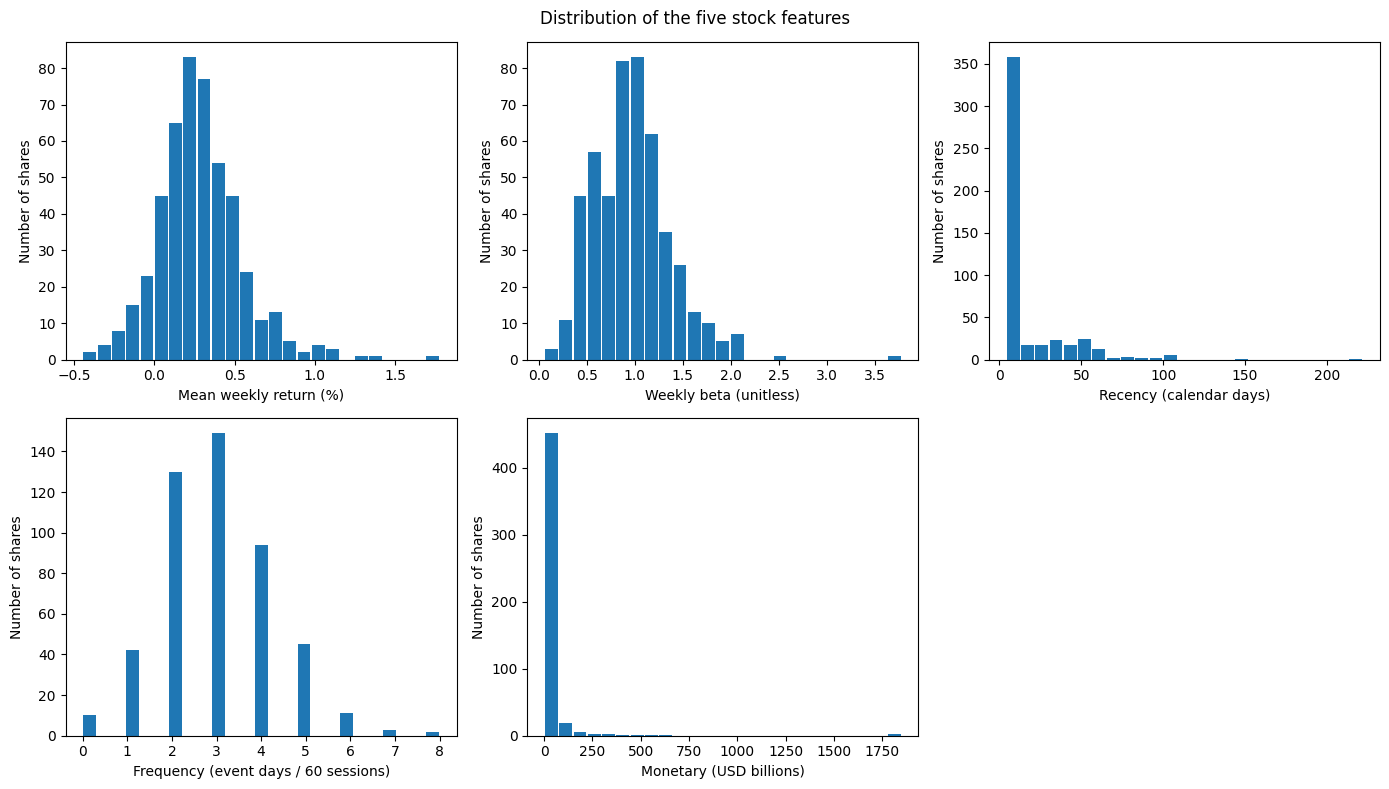

First rows of the feature table


,Security,GICS Sector,mean_weekly_return,weekly_beta,aligned_weeks,last_spike,recency,frequency,monetary
MMM,3M,Industrials,0.001142,0.869079,207,2024-12-20,11.0,4,2.599146e+10
AOS,A. O. Smith,Industrials,0.001991,1.042804,207,2024-12-20,11.0,2,4.748980e+09
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207,2024-12-20,11.0,1,3.523027e+10
ABBV,AbbVie,Health Care,0.003749,0.425366,207,2024-12-20,11.0,3,6.837054e+10
ACN,Accenture,Information Technology,0.002376,1.143301,207,2024-12-20,11.0,2,5.199430e+10
ADBE,Adobe Inc.,Information Technology,0.000990,1.553525,207,2024-12-13,18.0,3,1.030403e+11
AMD,Advanced Micro Devices,Information Technology,0.003624,1.877622,207,2024-12-13,18.0,4,3.131659e+11
AES,AES Corporation,Utilities,-0.001420,1.143912,207,2024-11-07,54.0,3,1.119578e+10


In [22]:
# the five features in easy units (return in %, Monetary in $ billions) for the summary
readable = pd.DataFrame({
    "mean weekly return (%)": model_data["mean_weekly_return"] * 100,
    "weekly beta": model_data["weekly_beta"],
    "recency (days)": model_data["recency"],
    "frequency (days)": model_data["frequency"],
    "monetary ($ bn)": model_data["monetary"] / 1e9,
})
# count, mean, sd, min, quartiles, max and skew for each feature
feature_summary = readable.describe().T
feature_summary["skew"] = readable.skew()
print("Feature summary in original units")
display(feature_summary)
feature_summary.to_csv(OUT_DIR / "feature_summary.csv")

# axis label for each feature, with its unit
axis_labels = {
    "mean weekly return (%)": "Mean weekly return (%)",
    "weekly beta": "Weekly beta (unitless)",
    "recency (days)": "Recency (calendar days)",
    "frequency (days)": "Frequency (event days / 60 sessions)",
    "monetary ($ bn)": "Monetary (USD billions)",
}

# one histogram per feature in a 2 x 3 grid
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), readable.columns):
    ax.hist(readable[col], bins=25, rwidth=0.9)   # small gap between bars
    ax.set_xlabel(axis_labels[col])
    ax.set_ylabel("Number of shares")
axes[1, 2].axis("off")                             # only five features, so the sixth panel is left empty
fig.suptitle("Distribution of the five stock features")
fig.tight_layout()
save_fig(fig, "feature_distributions")
plt.show()

# a preview of the final feature table
print("First rows of the feature table")
display(model_data[["Security", "GICS Sector", "mean_weekly_return", "weekly_beta", "aligned_weeks",
                    "last_spike", "recency", "frequency", "monetary"]].head(8))

Skew and outlier check (raw features and log1p Monetary)


,min,median,max,skew,iqr_outliers
mean_weekly_return,-4.468094e-03,2.618933e-03,1.777248e-02,0.867516,15
weekly_beta,5.545235e-02,9.506096e-01,3.778560e+00,1.103649,10
recency,4.000000e+00,1.100000e+01,2.220000e+02,3.645784,115
frequency,0.000000e+00,3.000000e+00,8.000000e+00,0.424735,2
monetary,1.297483e+09,1.668382e+10,1.847697e+12,11.683797,45
log_monetary,2.098369e+01,2.353770e+01,2.824496e+01,1.079057,13


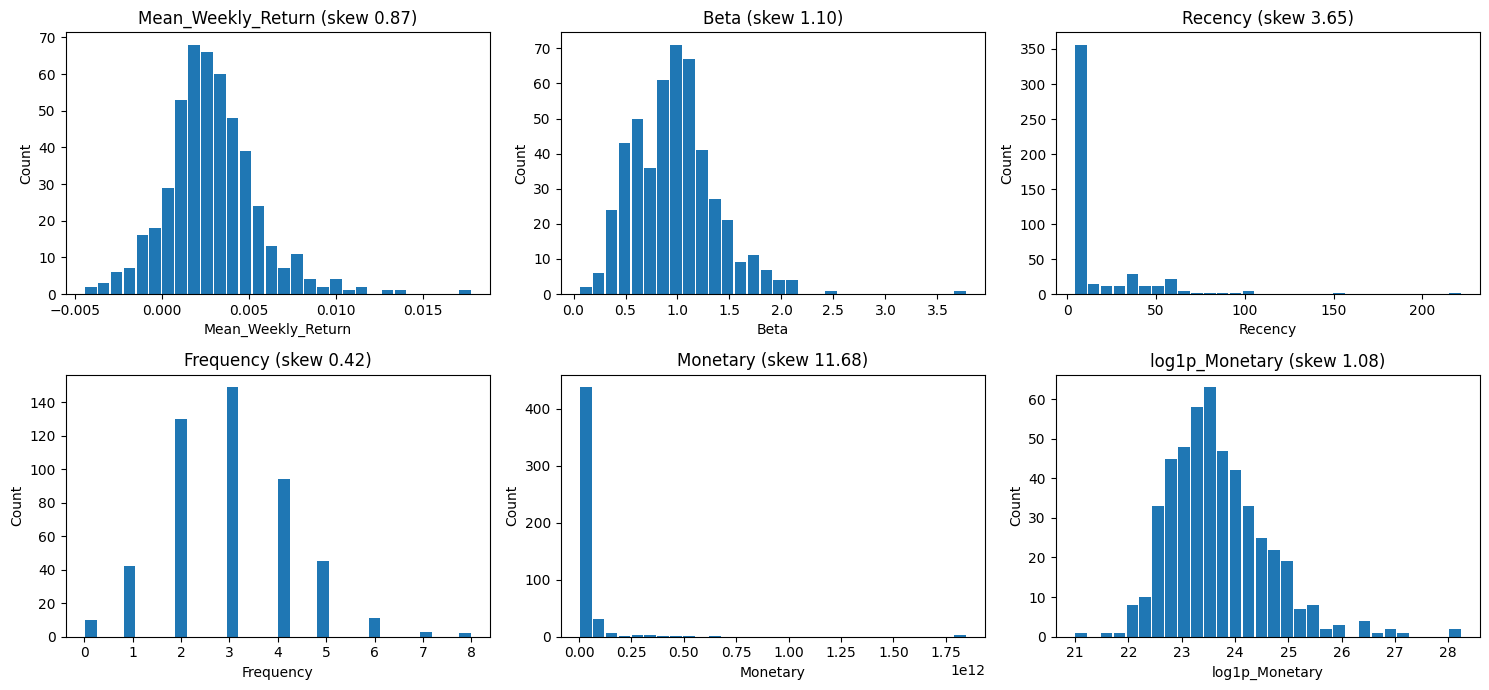

In [23]:
# 2.1 the two separate feature matrices (they are never merged into one score)
RISK_COLS = ["mean_weekly_return", "weekly_beta"]
ACTIVITY_COLS = ["recency", "frequency", "log_monetary"]

risk_raw = model_data[RISK_COLS]
# activity matrix: R and F as they are, Monetary through log1p to reduce its huge skew
activity_raw = model_data[["recency", "frequency"]].assign(log_monetary=np.log1p(model_data["monetary"]))
# both matrices must contain exactly the same shares
assert risk_raw.index.equals(activity_raw.index)


# count outliers with the 1.5 x IQR rule (below Q1 - 1.5 IQR or above Q3 + 1.5 IQR)
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    spread = q3 - q1
    return int(((s < q1 - 1.5 * spread) | (s > q3 + 1.5 * spread)).sum())


# skew and outlier table for every input, plus Monetary after log1p
diag_data = model_data[FEATURES].assign(log_monetary=activity_raw["log_monetary"])
diagnostics = pd.DataFrame({
    "min": diag_data.min(), "median": diag_data.median(), "max": diag_data.max(),
    "skew": diag_data.skew(), "iqr_outliers": diag_data.apply(iqr_outliers),
})
print("Skew and outlier check (raw features and log1p Monetary)")
display(diagnostics)

# every clustering input before scaling, plus Monetary after log1p, with its skew
panel_names = {
    "mean_weekly_return": "Mean_Weekly_Return",
    "weekly_beta": "Beta",
    "recency": "Recency",
    "frequency": "Frequency",
    "monetary": "Monetary",
    "log_monetary": "log1p_Monetary",
}

# one histogram per input, with its skew in the title
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (col, label) in zip(axes.ravel(), panel_names.items()):
    ax.hist(diag_data[col], bins=30, rwidth=0.9)
    ax.set(title=f"{label} (skew {diag_data[col].skew():.2f})", xlabel=label, ylabel="Count")
fig.tight_layout()
save_fig(fig, "skew_treatment")
plt.show()

In [24]:
# standardise each matrix separately: every column gets mean 0 and sd 1,
# so no feature dominates the distances just because of its units
risk_scaler = StandardScaler().fit(risk_raw)
activity_scaler = StandardScaler().fit(activity_raw)

X_risk = pd.DataFrame(risk_scaler.transform(risk_raw), index=risk_raw.index, columns=RISK_COLS)
X_activity = pd.DataFrame(activity_scaler.transform(activity_raw), index=activity_raw.index, columns=ACTIVITY_COLS)
# keep both scaled matrices together so the same code can loop over them
matrices = {"risk_return": X_risk, "activity": X_activity}

# check the scaling worked and count extreme values (more than 3 sd from the mean)
scaling_check = pd.concat({
    name: pd.DataFrame({"mean": X.mean(), "std": X.std(ddof=0), "shares beyond 3 sd": (X.abs() > 3).sum()})
    for name, X in matrices.items()
})
print("Standardised matrices (mean 0, sd 1)")
display(scaling_check.rename_axis(["matrix", "feature"]).reset_index())
print("Same shares in both matrices:", X_risk.index.equals(X_activity.index), "|", len(X_risk), "shares")

# save the scaled matrices
X_risk.to_csv(OUT_DIR / "matrix_risk_return_scaled.csv")
X_activity.to_csv(OUT_DIR / "matrix_activity_scaled.csv")

Standardised matrices (mean 0, sd 1)


,matrix,feature,mean,std,shares beyond 3 sd
0,risk_return,mean_weekly_return,6.944605e-17,1.0,6
1,risk_return,weekly_beta,6.579099e-17,1.0,2
2,activity,recency,-1.462022e-17,1.0,11
3,activity,frequency,-9.685896e-17,1.0,5
4,activity,log_monetary,-4.375101e-15,1.0,7


Same shares in both matrices: True | 486 shares


In [25]:
# cluster numbers from the algorithms are arbitrary, so they are renumbered in a fixed order
ORDER_BY = {"risk_return": model_data["weekly_beta"].to_numpy(),   # cluster 1 = lowest beta
            "activity": model_data["recency"].to_numpy()}          # cluster 1 = most recent activity


def ordered(labels, values):
    """Renumber clusters 1..k by the mean of `values`, so the numbers mean something."""
    means = pd.Series(values).groupby(np.asarray(labels)).mean().sort_values()
    mapping = {old: new for new, old in enumerate(means.index, start=1)}
    return np.array([mapping[label] for label in labels])


# cut the Ward tree into exactly k clusters
def ward_cut(tree, k):
    labels = fcluster(tree, t=k, criterion="maxclust")
    assert len(np.unique(labels)) == k
    return labels


# silhouette score plus the cluster sizes for one clustering
def evaluate(X, labels):
    sizes = pd.Series(labels).value_counts().sort_values(ascending=False)
    return {"silhouette": silhouette_score(X, labels), "smallest": int(sizes.min()),
            "smallest_pct": sizes.min() / len(labels), "sizes": " / ".join(map(str, sizes))}


# choose k: highest silhouette among the k values where every cluster has at least 5% of shares
# (a manual choice in K_CHOICE overrides this)
def pick_k(grid, key):
    if key in K_CHOICE:
        return int(K_CHOICE[key]), "manual choice (see K_CHOICE)"
    eligible = grid[grid["eligible"]]
    if eligible.empty:
        return int(grid["silhouette"].idxmax()), "highest silhouette (no k met the size rule)"
    return int(eligible["silhouette"].idxmax()), "highest silhouette with every cluster at least 5%"


# cluster profile in original units (mean and median of each feature per cluster)
def profile(labels, matrix):
    data = model_data.assign(cluster=np.asarray(labels))
    groups = data.groupby("cluster")
    if matrix == "risk_return":
        return pd.DataFrame({
            "shares": groups.size(),
            "return_pct_mean": groups["mean_weekly_return"].mean() * 100,
            "return_pct_median": groups["mean_weekly_return"].median() * 100,
            "beta_mean": groups["weekly_beta"].mean(),
            "beta_median": groups["weekly_beta"].median(),
        })
    return pd.DataFrame({
        "shares": groups.size(),
        "recency_mean": groups["recency"].mean(),
        "recency_median": groups["recency"].median(),
        "frequency_mean": groups["frequency"].mean(),
        "frequency_median": groups["frequency"].median(),
        "monetary_bn_mean": groups["monetary"].mean() / 1e9,
        "monetary_bn_median": groups["monetary"].median() / 1e9,
    })


# 2.2 build the full Ward tree (Euclidean distance) for each matrix
ward_trees = {name: linkage(X.to_numpy(), method="ward", metric="euclidean") for name, X in matrices.items()}
ward_grid, chosen, chosen_why = {}, {}, {}

for name, X in matrices.items():
    # try every k from 2 to 8 and score it
    rows = {k: evaluate(X, ward_cut(ward_trees[name], k)) for k in K_VALUES}
    grid = pd.DataFrame(rows).T.astype({"silhouette": float, "smallest": int, "smallest_pct": float})
    grid["eligible"] = grid["smallest_pct"] >= MIN_CLUSTER_PCT
    grid.index.name = "k"
    ward_grid[name] = grid
    chosen[f"ward_{name}"], chosen_why[f"ward_{name}"] = pick_k(grid, f"ward_{name}")
    print(f"Ward, {name.replace('_', ' ')}: silhouette and cluster sizes for k = 2 to 8")
    display(grid)

print("Selected k for Ward")
display(pd.DataFrame({"k": {key: chosen[key] for key in chosen},
                     "reason": {key: chosen_why[key] for key in chosen}}))

Ward, risk return: silhouette and cluster sizes for k = 2 to 8


,silhouette,smallest,smallest_pct,sizes,eligible
k,,,,,
2,0.339485,92,0.189300,394 / 92,True
3,0.273834,92,0.189300,230 / 164 / 92,True
4,0.282115,48,0.098765,182 / 164 / 92 / 48,True
5,0.304135,48,0.098765,182 / 98 / 92 / 66 / 48,True
6,0.320409,5,0.010288,182 / 98 / 87 / 66 / 48 / 5,False
7,0.323951,5,0.010288,160 / 98 / 87 / 66 / 48 / 22 / 5,False
8,0.320779,5,0.010288,160 / 98 / 66 / 56 / 48 / 31 / 22 / 5,False


Ward, activity: silhouette and cluster sizes for k = 2 to 8


,silhouette,smallest,smallest_pct,sizes,eligible
k,,,,,
2,0.368024,82,0.168724,404 / 82,True
3,0.303979,82,0.168724,250 / 154 / 82,True
4,0.288765,43,0.088477,207 / 154 / 82 / 43,True
5,0.304982,10,0.020576,207 / 154 / 72 / 43 / 10,False
6,0.314364,10,0.020576,207 / 136 / 72 / 43 / 18 / 10,False
7,0.291672,10,0.020576,141 / 136 / 72 / 66 / 43 / 18 / 10,False
8,0.302100,10,0.020576,141 / 79 / 72 / 66 / 57 / 43 / 18 / 10,False


Selected k for Ward


,k,reason
ward_risk_return,2,highest silhouette with every cluster at least 5%
ward_activity,2,highest silhouette with every cluster at least 5%


In [26]:
# profiles in original units for every k that passed the size rule (plus the pick)
for name in matrices:
    ks = sorted(set(ward_grid[name].index[ward_grid[name]["eligible"]]) | {chosen[f"ward_{name}"]})
    candidates = pd.concat({
        k: profile(ordered(ward_cut(ward_trees[name], k), ORDER_BY[name]), name) for k in ks
    }, names=["k", "cluster"])
    print(f"Ward {name.replace('_', ' ')}: candidate profiles in original units")
    display(candidates.reset_index())

Ward risk return: candidate profiles in original units


,k,cluster,shares,return_pct_mean,return_pct_median,beta_mean,beta_median
0,2,1,394,0.204832,0.209320,0.897950,0.881695
1,2,2,92,0.632119,0.550330,1.298084,1.217711
2,3,1,164,0.287475,0.327292,0.601184,0.577699
3,3,2,230,0.145904,0.171462,1.109557,1.038413
4,3,3,92,0.632119,0.550330,1.298084,1.217711
5,4,1,164,0.287475,0.327292,0.601184,0.577699
6,4,2,182,0.131664,0.166138,0.972836,0.964427
7,4,3,92,0.632119,0.550330,1.298084,1.217711
8,4,4,48,0.199896,0.252418,1.627957,1.513851
9,5,1,66,0.087893,0.113371,0.438973,0.448500


Ward activity: candidate profiles in original units


,k,cluster,shares,recency_mean,recency_median,frequency_mean,frequency_median,monetary_bn_mean,monetary_bn_median
0,2,1,404,12.715347,11.0,3.170792,3.0,37.830201,16.047278
1,2,2,82,58.304878,54.5,2.097561,2.0,47.158977,17.849027
2,3,1,250,12.120000,11.0,3.360000,3.0,11.764133,11.177613
3,3,2,154,13.681818,11.0,2.863636,3.0,80.145246,39.695450
4,3,3,82,58.304878,54.5,2.097561,2.0,47.158977,17.849027
5,4,1,207,11.140097,11.0,2.942029,3.0,11.099806,10.785266
6,4,2,154,13.681818,11.0,2.863636,3.0,80.145246,39.695450
7,4,3,43,16.837209,11.0,5.372093,5.0,14.962176,14.429973
8,4,4,82,58.304878,54.5,2.097561,2.0,47.158977,17.849027


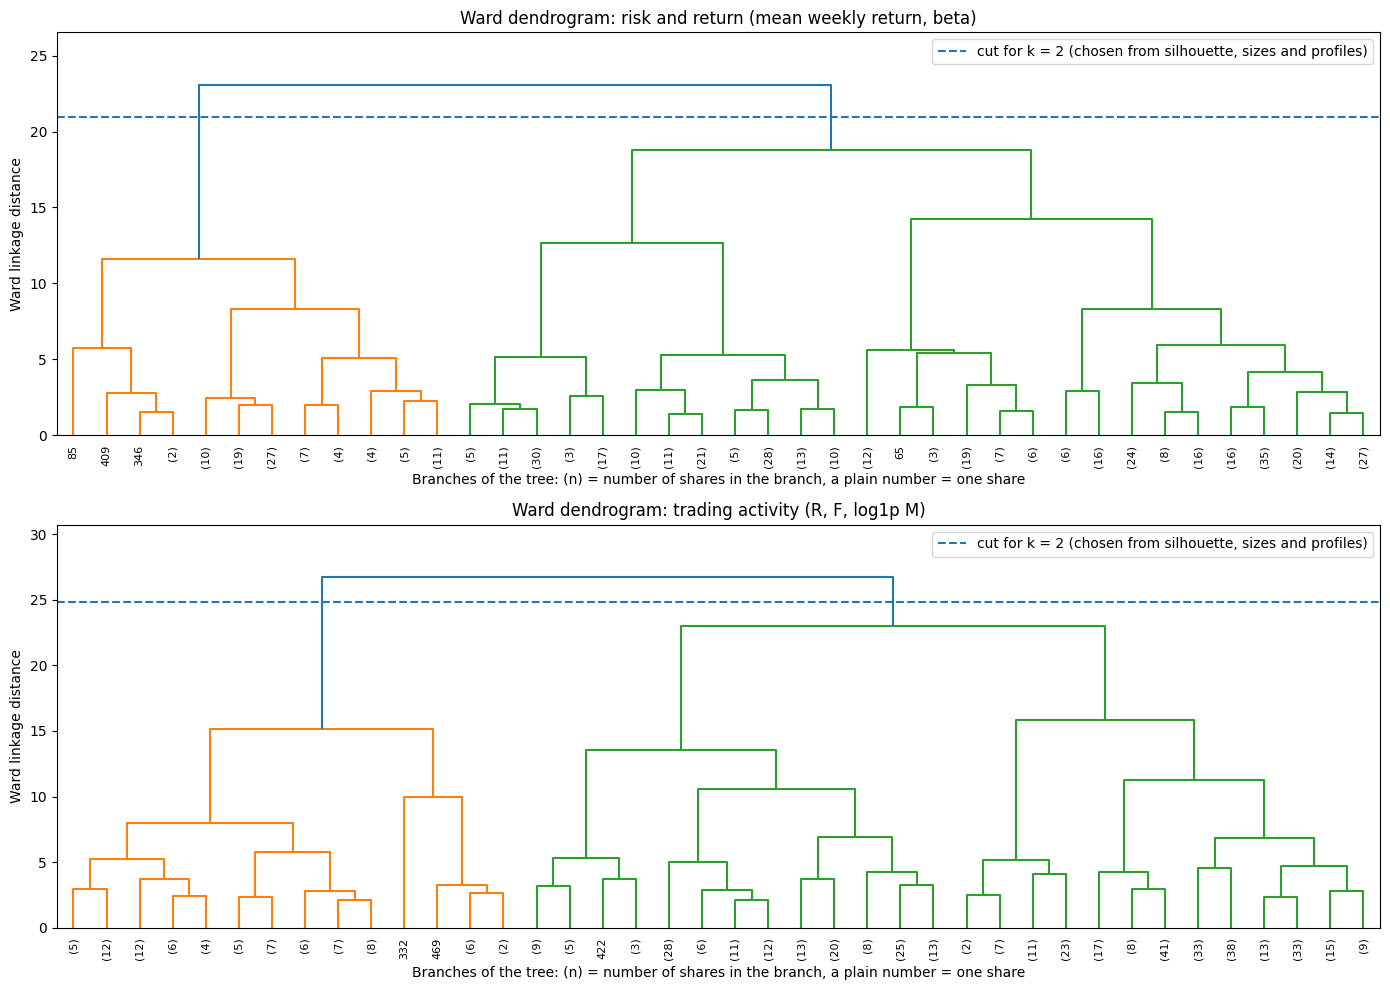

risk_return: scipy cut vs scikit-learn Ward, adjusted Rand index = 1.0
activity: scipy cut vs scikit-learn Ward, adjusted Rand index = 1.0


In [27]:
# where to draw the cut line on the dendrogram for the chosen k
def cut_height(tree, k):
    # halfway between the merge that leaves k clusters and the next one up
    return (tree[-k, 2] + tree[-(k - 1), 2]) / 2


fig, axes = plt.subplots(2, 1, figsize=(14, 10))
titles = {"risk_return": "risk and return (mean weekly return, beta)",
          "activity": "trading activity (R, F, log1p M)"}

for ax, name in zip(axes, matrices):
    k = chosen[f"ward_{name}"]
    # only the last 40 merges are drawn (truncate_mode), otherwise 486 leaves would be unreadable
    # branches below the cut line share a colour, so the colours match the chosen k
    dendrogram(ward_trees[name], ax=ax, truncate_mode="lastp", p=40, show_leaf_counts=True,
               leaf_font_size=8, leaf_rotation=90, color_threshold=cut_height(ward_trees[name], k))
    ax.axhline(cut_height(ward_trees[name], k), ls="--", lw=1.5,
               label=f"cut for k = {k} (chosen from silhouette, sizes and profiles)")
    ax.set_title(f"Ward dendrogram: {titles[name]}")
    ax.set_ylabel("Ward linkage distance")
    ax.set_xlabel("Branches of the tree: (n) = number of shares in the branch, a plain number = one share")
    ax.set_ylim(0, ward_trees[name][-1, 2] * 1.15)
    ax.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "ward_dendrograms")
plt.show()

# the same partition from scikit-learn, as a check that the cut is right
for name, X in matrices.items():
    k = chosen[f"ward_{name}"]
    sk_labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    print(f"{name}: scipy cut vs scikit-learn Ward, adjusted Rand index =",
          round(adjusted_rand_score(ward_cut(ward_trees[name], k), sk_labels), 4))

K-means, risk return: inertia, silhouette and sizes for k = 2 to 8


,inertia,silhouette,smallest,smallest_pct,sizes,eligible
k,,,,,,
2,621.634376,0.386950,143,0.294239,343 / 143,True
3,461.178681,0.328907,119,0.244856,202 / 165 / 119,True
4,371.577025,0.326978,40,0.082305,160 / 154 / 132 / 40,True
5,309.613027,0.340589,27,0.055556,166 / 131 / 112 / 50 / 27,True
6,265.448125,0.333885,5,0.010288,158 / 113 / 111 / 56 / 43 / 5,False
7,227.476228,0.331472,5,0.010288,143 / 85 / 83 / 74 / 48 / 48 / 5,False
8,194.361615,0.354243,5,0.010288,136 / 79 / 78 / 76 / 43 / 40 / 29 / 5,False


K-means, activity: inertia, silhouette and sizes for k = 2 to 8


,inertia,silhouette,smallest,smallest_pct,sizes,eligible
k,,,,,,
2,1066.831882,0.423122,68,0.139918,418 / 68,True
3,796.614361,0.324976,64,0.131687,270 / 152 / 64,True
4,609.832467,0.340867,61,0.125514,212 / 122 / 91 / 61,True
5,514.713552,0.357755,11,0.022634,198 / 122 / 87 / 68 / 11,False
6,437.422370,0.345505,11,0.022634,141 / 120 / 104 / 69 / 41 / 11,False
7,386.286196,0.347447,1,0.002058,141 / 120 / 104 / 68 / 41 / 11 / 1,False
8,342.174866,0.350304,1,0.002058,140 / 106 / 83 / 66 / 64 / 15 / 11 / 1,False


Selected k for all four solutions


,k,reason
ward_risk_return,2,highest silhouette with every cluster at least 5%
ward_activity,2,highest silhouette with every cluster at least 5%
kmeans_risk_return,2,highest silhouette with every cluster at least 5%
kmeans_activity,2,highest silhouette with every cluster at least 5%


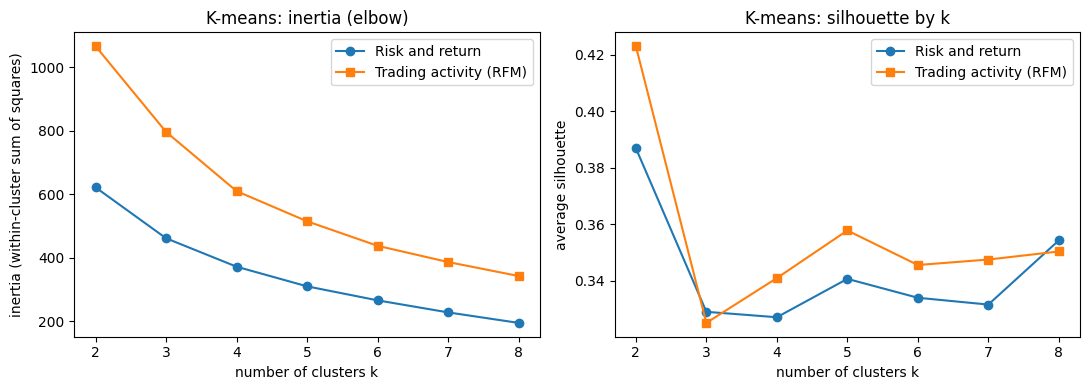

In [28]:
# 2.3 K-means with a fixed seed and 25 k-means++ starts (the best of the 25 is kept)
def fit_kmeans(X, k, seed=SEED, n_init=N_INIT):
    return KMeans(n_clusters=k, n_init=n_init, random_state=seed, init="k-means++").fit(X)


# for every k from 2 to 8: inertia, silhouette and cluster sizes for each matrix
kmeans_grid = {}
for name, X in matrices.items():
    rows = {}
    for k in K_VALUES:
        model = fit_kmeans(X, k)
        # labels_ start at 0, so + 1 numbers the clusters 1, 2, 3 ... like Ward
        rows[k] = {"inertia": model.inertia_, **evaluate(X, model.labels_ + 1)}
    grid = pd.DataFrame(rows).T.astype({"inertia": float, "silhouette": float, "smallest": int, "smallest_pct": float})
    grid["eligible"] = grid["smallest_pct"] >= MIN_CLUSTER_PCT
    grid.index.name = "k"
    kmeans_grid[name] = grid
    chosen[f"kmeans_{name}"], chosen_why[f"kmeans_{name}"] = pick_k(grid, f"kmeans_{name}")
    print(f"K-means, {name.replace('_', ' ')}: inertia, silhouette and sizes for k = 2 to 8")
    display(grid)

# the k picked for each of the four solutions and why
print("Selected k for all four solutions")
display(pd.DataFrame({"k": chosen, "reason": chosen_why}))

# K-means diagnostics for both matrices: inertia (elbow) on the left, silhouette on the right
line_labels = {"risk_return": "Risk and return", "activity": "Trading activity (RFM)"}
markers = {"risk_return": "o-", "activity": "s-"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in matrices:
    axes[0].plot(list(K_VALUES), kmeans_grid[name]["inertia"], markers[name], label=line_labels[name])
    axes[1].plot(list(K_VALUES), kmeans_grid[name]["silhouette"], markers[name], label=line_labels[name])

axes[0].set(title="K-means: inertia (elbow)", xlabel="number of clusters k",
            ylabel="inertia (within-cluster sum of squares)")
axes[1].set(title="K-means: silhouette by k", xlabel="number of clusters k", ylabel="average silhouette")
for ax in axes:
    ax.legend()
fig.tight_layout()
save_fig(fig, "k_selection_diagnostics")
plt.show()

In [29]:
# how much does the starting point matter? single starts vs the 25-start setting
stability = []
for name, X in matrices.items():
    k = chosen[f"kmeans_{name}"]
    reference = fit_kmeans(X, k).labels_
    # refit with 10 different seeds, once with a single start and once with 25 starts,
    # and compare each result with the seed 42 solution using the adjusted Rand index
    for setting, n_init in [("1 start", 1), (f"{N_INIT} starts", N_INIT)]:
        fits = [fit_kmeans(X, k, seed=s, n_init=n_init) for s in range(10)]
        aris = [adjusted_rand_score(reference, f.labels_) for f in fits]
        inertias = [f.inertia_ for f in fits]
        stability.append({"matrix": name, "k": k, "setting": setting, "seeds tried": 10,
                          "lowest ARI vs seed 42": min(aris), "mean ARI": np.mean(aris),
                          "inertia min": min(inertias), "inertia max": max(inertias)})
print("K-means initialisation check (seeds 0 to 9)")
display(pd.DataFrame(stability).set_index(["matrix", "setting"]).reset_index())

for name in matrices:
    # profiles in original units for each k that passed the size rule
    ks = sorted(set(kmeans_grid[name].index[kmeans_grid[name]["eligible"]]) | {chosen[f"kmeans_{name}"]})
    candidates = pd.concat({
        k: profile(ordered(fit_kmeans(matrices[name], k).labels_ + 1, ORDER_BY[name]), name) for k in ks
    }, names=["k", "cluster"])
    print(f"K-means {name.replace('_', ' ')}: candidate profiles in original units")
    display(candidates.reset_index())

K-means initialisation check (seeds 0 to 9)


,matrix,setting,k,seeds tried,lowest ARI vs seed 42,mean ARI,inertia min,inertia max
0,risk_return,1 start,2,10,1.000000,1.000000,621.634376,621.653821
1,risk_return,25 starts,2,10,1.000000,1.000000,621.634376,621.653821
2,activity,1 start,2,10,-0.005445,0.652511,1066.831882,1132.179474
3,activity,25 starts,2,10,1.000000,1.000000,1066.831882,1066.831882


K-means risk return: candidate profiles in original units


,k,cluster,shares,return_pct_mean,return_pct_median,beta_mean,beta_median
0,2,1,343,0.182605,0.191723,0.816607,0.833991
1,2,2,143,0.533042,0.486062,1.350487,1.278113
2,3,1,202,0.259335,0.258536,0.630817,0.621536
3,3,2,165,0.094561,0.117943,1.139090,1.080530
4,3,3,119,0.595549,0.527538,1.326396,1.221440
5,4,1,154,0.168989,0.186905,0.576641,0.576692
6,4,2,160,0.454441,0.432807,0.982972,0.985115
7,4,3,132,0.084191,0.113197,1.203014,1.141830
8,4,4,40,0.725264,0.700667,1.708495,1.680880
9,5,1,131,0.205674,0.203391,0.533487,0.530359


K-means activity: candidate profiles in original units


,k,cluster,shares,recency_mean,recency_median,frequency_mean,frequency_median,monetary_bn_mean,monetary_bn_median
0,2,1,418,13.423445,11.0,3.186603,3.0,32.691002,15.569619
1,2,2,68,63.338235,55.0,1.779412,2.0,80.670567,22.250045
2,3,1,270,13.366667,11.0,3.351852,3.0,12.013944,11.370675
3,3,2,152,14.302632,11.0,2.894737,3.0,81.729111,41.602418
4,3,3,64,64.609375,55.0,1.687500,2.0,54.435118,21.147355
5,4,1,212,13.264151,11.0,2.367925,2.0,15.175306,13.336412
6,4,2,122,13.942623,11.0,4.549180,4.0,15.015388,12.825893
7,4,3,91,15.142857,11.0,3.230769,3.0,117.301205,60.183441
8,4,4,61,66.016393,55.0,1.672131,2.0,56.180087,21.242121


In [30]:
# 2.4 the final cluster label of every share in each of the four baseline solutions
assignments = model_data[["Security", "GICS Sector"]].copy()
for name, X in matrices.items():
    assignments[f"ward_{name}"] = ordered(ward_cut(ward_trees[name], chosen[f"ward_{name}"]), ORDER_BY[name])
    assignments[f"kmeans_{name}"] = ordered(fit_kmeans(X, chosen[f"kmeans_{name}"]).labels_ + 1, ORDER_BY[name])
assignments.to_csv(OUT_DIR / "cluster_assignments.csv")

SOLUTIONS = {"ward_risk_return": "risk_return", "kmeans_risk_return": "risk_return",
             "ward_activity": "activity", "kmeans_activity": "activity"}


# Kaufman and Rousseeuw guide for reading the silhouette value
def strength(s):
    return "none" if s < 0.25 else "weak" if s < 0.5 else "reasonable" if s < 0.7 else "strong"


# one row per solution: k, silhouette and cluster sizes
solution_summary = pd.DataFrame([
    {"solution": sol, "k": chosen[sol],
     "silhouette": silhouette_score(matrices[mat], assignments[sol]),
     "cluster sizes": " / ".join(map(str, assignments[sol].value_counts().sort_index()))}
    for sol, mat in SOLUTIONS.items()
]).set_index("solution")
solution_summary["structure (Kaufman and Rousseeuw)"] = solution_summary["silhouette"].map(strength)
print("The four baseline solutions")
display(solution_summary)

for mat in matrices:
    # Ward and K-means profiles side by side for the same matrix
    both = pd.concat({"Ward": profile(assignments[f"ward_{mat}"], mat),
                      "K-means": profile(assignments[f"kmeans_{mat}"], mat)}, names=["algorithm", "cluster"])
    print(f"{mat.replace('_', ' ').capitalize()} profiles in original units")
    display(both.reset_index())
    both.to_csv(OUT_DIR / f"profiles_{mat}.csv")

The four baseline solutions


,k,silhouette,cluster sizes,structure (Kaufman and Rousseeuw)
solution,,,,
ward_risk_return,2,0.339485,394 / 92,weak
kmeans_risk_return,2,0.386950,343 / 143,weak
ward_activity,2,0.368024,404 / 82,weak
kmeans_activity,2,0.423122,418 / 68,weak


Risk return profiles in original units


,algorithm,cluster,shares,return_pct_mean,return_pct_median,beta_mean,beta_median
0,Ward,1,394,0.204832,0.209320,0.897950,0.881695
1,Ward,2,92,0.632119,0.550330,1.298084,1.217711
2,K-means,1,343,0.182605,0.191723,0.816607,0.833991
3,K-means,2,143,0.533042,0.486062,1.350487,1.278113


Activity profiles in original units


,algorithm,cluster,shares,recency_mean,recency_median,frequency_mean,frequency_median,monetary_bn_mean,monetary_bn_median
0,Ward,1,404,12.715347,11.0,3.170792,3.0,37.830201,16.047278
1,Ward,2,82,58.304878,54.5,2.097561,2.0,47.158977,17.849027
2,K-means,1,418,13.423445,11.0,3.186603,3.0,32.691002,15.569619
3,K-means,2,68,63.338235,55.0,1.779412,2.0,80.670567,22.250045


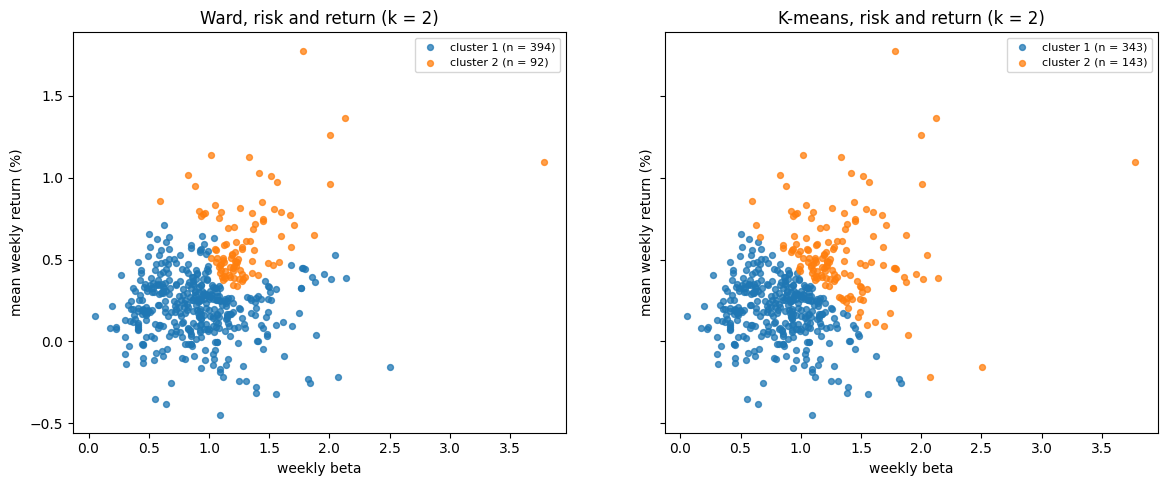

PCA of the activity matrix (two components keep 79% of the variance)


,PC1 loading,PC2 loading
recency,0.711302,0.022844
frequency,-0.649887,0.402119
log_monetary,0.267762,0.915302
explained variance,0.457936,0.336473


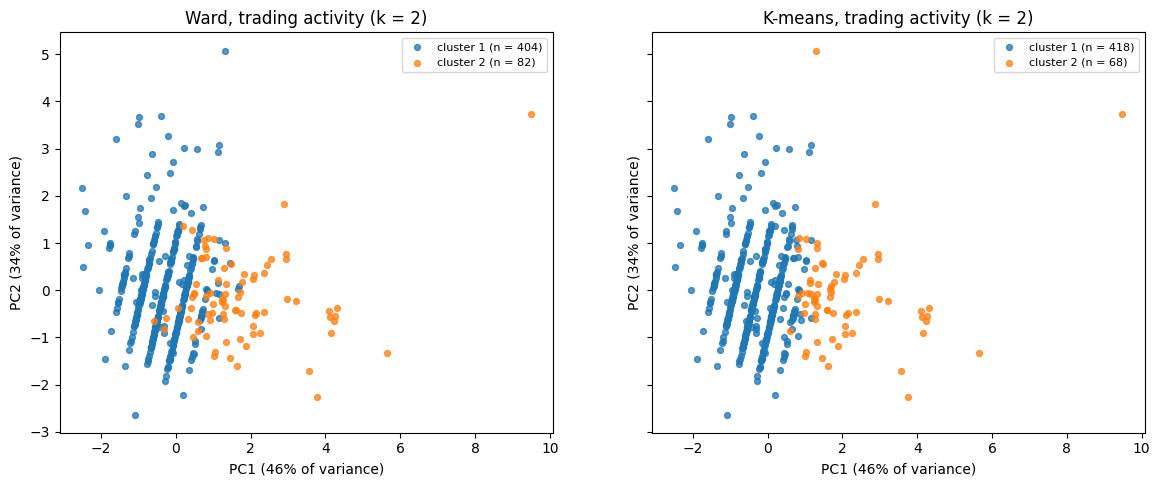

In [31]:
# scatter plot with one colour per cluster and the cluster size in the legend
def scatter_clusters(ax, x, y, labels, title, xlabel, ylabel):
    for c in sorted(np.unique(labels)):
        mask = labels == c
        ax.scatter(x[mask], y[mask], s=18, alpha=0.75, label=f"cluster {c} (n = {mask.sum()})")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend(fontsize=8, loc="best")


fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
# risk and return has only two features, so it is plotted directly (beta against return)
for ax, sol, label in zip(axes, ["ward_risk_return", "kmeans_risk_return"], ["Ward", "K-means"]):
    scatter_clusters(ax, model_data["weekly_beta"].to_numpy(), model_data["mean_weekly_return"].to_numpy() * 100,
                     assignments[sol].to_numpy(), f"{label}, risk and return (k = {chosen[sol]})",
                     "weekly beta", "mean weekly return (%)")
save_fig(fig, "clusters_risk_return")
plt.show()

# the activity matrix has three features, so PCA squeezes it into two axes for the plot
# (the clusters themselves were found on all three features)
pca = PCA(n_components=2).fit(X_activity)
pcs = pca.transform(X_activity)
# loadings show how much each feature contributes to each axis
pca_info = pd.DataFrame(pca.components_.T, index=ACTIVITY_COLS, columns=["PC1 loading", "PC2 loading"])
pca_info.loc["explained variance"] = pca.explained_variance_ratio_
print(f"PCA of the activity matrix (two components keep {pca.explained_variance_ratio_.sum():.0%} of the variance)")
display(pca_info)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
for ax, sol, label in zip(axes, ["ward_activity", "kmeans_activity"], ["Ward", "K-means"]):
    scatter_clusters(ax, pcs[:, 0], pcs[:, 1], assignments[sol].to_numpy(),
                     f"{label}, trading activity (k = {chosen[sol]})",
                     f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
                     f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
save_fig(fig, "clusters_activity_pca")
plt.show()

In [32]:
# compare Ward and K-means on the same shares with a cross-table and the adjusted Rand index
comparison = []
for mat, X in matrices.items():
    ward_labels = assignments[f"ward_{mat}"]
    km_labels = assignments[f"kmeans_{mat}"]
    # K-means refitted at Ward's k, so the two methods can also be compared at the same k
    km_same_k = fit_kmeans(X, chosen[f"ward_{mat}"]).labels_
    print(f"{mat.replace('_', ' ').capitalize()}: shares by Ward cluster (rows) and K-means cluster (columns)")
    display(pd.crosstab(ward_labels.rename("Ward"), km_labels.rename("K-means")))
    comparison.append({"matrix": mat, "k Ward": chosen[f"ward_{mat}"], "k K-means": chosen[f"kmeans_{mat}"],
                       "ARI selected solutions": adjusted_rand_score(ward_labels, km_labels),
                       "ARI at the same k (Ward's k)": adjusted_rand_score(ward_labels, km_same_k),
                       "silhouette Ward": silhouette_score(X, ward_labels),
                       "silhouette K-means": silhouette_score(X, km_labels)})
algorithm_comparison = pd.DataFrame(comparison).set_index("matrix")
print("Ward against K-means on the same shares")
display(algorithm_comparison)
algorithm_comparison.to_csv(OUT_DIR / "algorithm_comparison.csv")

Risk return: shares by Ward cluster (rows) and K-means cluster (columns)


K-means,1,2
Ward,,
1,343,51
2,0,92


Activity: shares by Ward cluster (rows) and K-means cluster (columns)


K-means,1,2
Ward,,
1,396,8
2,22,60


Ward against K-means on the same shares


,k Ward,k K-means,ARI selected solutions,ARI at the same k (Ward's k),silhouette Ward,silhouette K-means
matrix,,,,,,
risk_return,2,2,0.597555,0.597555,0.339485,0.386950
activity,2,2,0.699819,0.699819,0.368024,0.423122


Correlations among R, F and log1p(M)


,method,feature,recency,frequency,log1p_monetary
0,Pearson,recency,1.000000,-0.346344,0.152394
1,Pearson,frequency,-0.346344,1.000000,0.012782
2,Pearson,log1p_monetary,0.152394,0.012782,1.000000
3,Spearman (rank),recency,1.000000,-0.195778,0.137157
4,Spearman (rank),frequency,-0.195778,1.000000,-0.047563
5,Spearman (rank),log1p_monetary,0.137157,-0.047563,1.000000


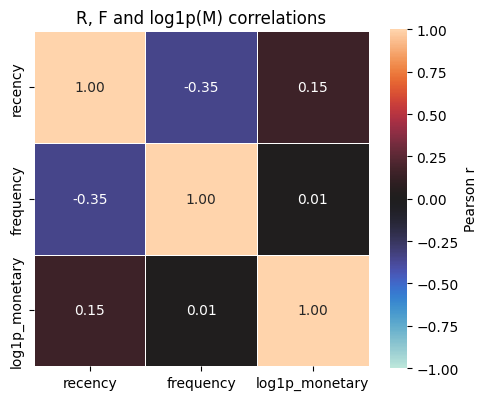

In [33]:
# 2.5.1 correlations between R, F and log1p(M) (Pearson, plus Spearman as a rank-based check)
corr_input = activity_raw.rename(columns={"log_monetary": "log1p_monetary"})
pearson = corr_input.corr(method="pearson")
spearman = corr_input.corr(method="spearman")
print("Correlations among R, F and log1p(M)")
display(pd.concat({"Pearson": pearson, "Spearman (rank)": spearman}, names=["method", "feature"]).reset_index())
pearson.to_csv(OUT_DIR / "rfm_correlations.csv")

# heatmap of the Pearson correlations
fig, ax = plt.subplots(figsize=(5.4, 4.4))
sns.heatmap(pearson, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("R, F and log1p(M) correlations")
save_fig(fig, "rfm_correlation_heatmap")
plt.show()

In [34]:
# 2.5.2 rerun the chosen Ward activity solution without Monetary: same shares, same k,
# and the two remaining features (R and F) standardised again from scratch
k_activity = chosen["ward_activity"]
rf_raw = model_data[["recency", "frequency"]]
X_rf = pd.DataFrame(StandardScaler().fit_transform(rf_raw), index=rf_raw.index, columns=rf_raw.columns)
rf_tree = linkage(X_rf.to_numpy(), method="ward", metric="euclidean")

# cluster labels with Monetary (original solution) and without Monetary (new solution)
with_m = assignments["ward_activity"].to_numpy()
without_m = ordered(ward_cut(rf_tree, k_activity), ORDER_BY["activity"])
assignments["ward_activity_without_m"] = without_m
assignments.to_csv(OUT_DIR / "cluster_assignments.csv")

# ARI near 1 = memberships barely change, so Monetary adds little at this k
ari_without_m = adjusted_rand_score(with_m, without_m)
print(f"Shares: {len(X_rf)} | k = {k_activity} | ARI with M vs without M = {ari_without_m:.3f}")
print("Membership with and without Monetary")
display(pd.crosstab(pd.Series(with_m, name="with Monetary"), pd.Series(without_m, name="R and F only")))


# traded value (Monetary) per cluster, to see whether Monetary separates liquidity levels
def traded_value_profile(labels):
    data = model_data.assign(cluster=labels)
    groups = data.groupby("cluster")
    return pd.DataFrame({
        "shares": groups.size(),
        "monetary_bn_median": groups["monetary"].median() / 1e9,
        "monetary_bn_mean": groups["monetary"].mean() / 1e9,
        "recency_median": groups["recency"].median(),
        "frequency_mean": groups["frequency"].mean(),
    })


print("Traded value profiles")
display(pd.concat({"with M": traded_value_profile(with_m), "R and F only": traded_value_profile(without_m)},
                  names=["solution", "cluster"]).reset_index())


# eta squared = share of a feature's variance explained by the clusters (0 = none, 1 = all)
def eta_squared(values, labels):
    values = pd.Series(np.asarray(values, dtype=float))
    group_means = values.groupby(np.asarray(labels)).transform("mean")
    return ((group_means - values.mean()) ** 2).sum() / ((values - values.mean()) ** 2).sum()


eta = pd.DataFrame({
    "with M": {col: eta_squared(activity_raw[col], with_m) for col in ACTIVITY_COLS},
    "R and F only": {col: eta_squared(activity_raw[col], without_m) for col in ACTIVITY_COLS},
})
print("Share of each feature's variance explained by the clusters (eta squared)")
display(eta)
eta.to_csv(OUT_DIR / "monetary_removal_eta_squared.csv")

Shares: 486 | k = 2 | ARI with M vs without M = 0.873
Membership with and without Monetary


R and F only,1,2
with Monetary,,
1,394,10
2,3,79


Traded value profiles


,solution,cluster,shares,monetary_bn_median,monetary_bn_mean,recency_median,frequency_mean
0,with M,1,404,16.047278,37.830201,11.0,3.170792
1,with M,2,82,17.849027,47.158977,54.5,2.097561
2,R and F only,1,397,15.463998,37.806801,11.0,3.209068
3,R and F only,2,89,20.847810,46.529630,54.0,2.011236


Share of each feature's variance explained by the clusters (eta squared)


,with M,R and F only
recency,0.641297,0.644656
frequency,0.091407,0.121442
log_monetary,0.001036,0.003685


In [35]:
# 3.2.1 risk-return clusters against activity clusters, on the same shares
rr, act = assignments["ward_risk_return"], assignments["ward_activity"]
print("Ward risk-return clusters (rows) against Ward activity clusters (columns)")
display(pd.crosstab(rr.rename("risk-return cluster"), act.rename("activity cluster"), margins=True))
print(f"ARI between the risk-return and activity groupings: {adjusted_rand_score(rr, act):.3f}")

# median of all five features in each cluster, in original units
all_five = pd.DataFrame({
    "return_pct": model_data["mean_weekly_return"] * 100, "beta": model_data["weekly_beta"],
    "recency": model_data["recency"], "frequency": model_data["frequency"],
    "monetary_bn": model_data["monetary"] / 1e9,
})
five_profiles = pd.concat({
    "risk-return": all_five.groupby(rr).median().assign(shares=rr.value_counts()),
    "activity": all_five.groupby(act).median().assign(shares=act.value_counts()),
}, names=["Ward solution", "cluster"])
print("Median of all five features by cluster (original units)")
display(five_profiles.reset_index())
five_profiles.to_csv(OUT_DIR / "five_feature_profiles.csv")

Ward risk-return clusters (rows) against Ward activity clusters (columns)


activity cluster,1,2,All
risk-return cluster,,,
1,331,63,394
2,73,19,92
All,404,82,486


ARI between the risk-return and activity groupings: 0.029
Median of all five features by cluster (original units)


,Ward solution,cluster,return_pct,beta,recency,frequency,monetary_bn,shares
0,risk-return,1,0.209320,0.881695,11.0,3.0,15.325160,394
1,risk-return,2,0.550330,1.217711,11.0,3.0,24.184129,92
2,activity,1,0.268899,0.935006,11.0,3.0,16.047278,404
3,activity,2,0.244400,1.046557,54.5,2.0,17.849027,82


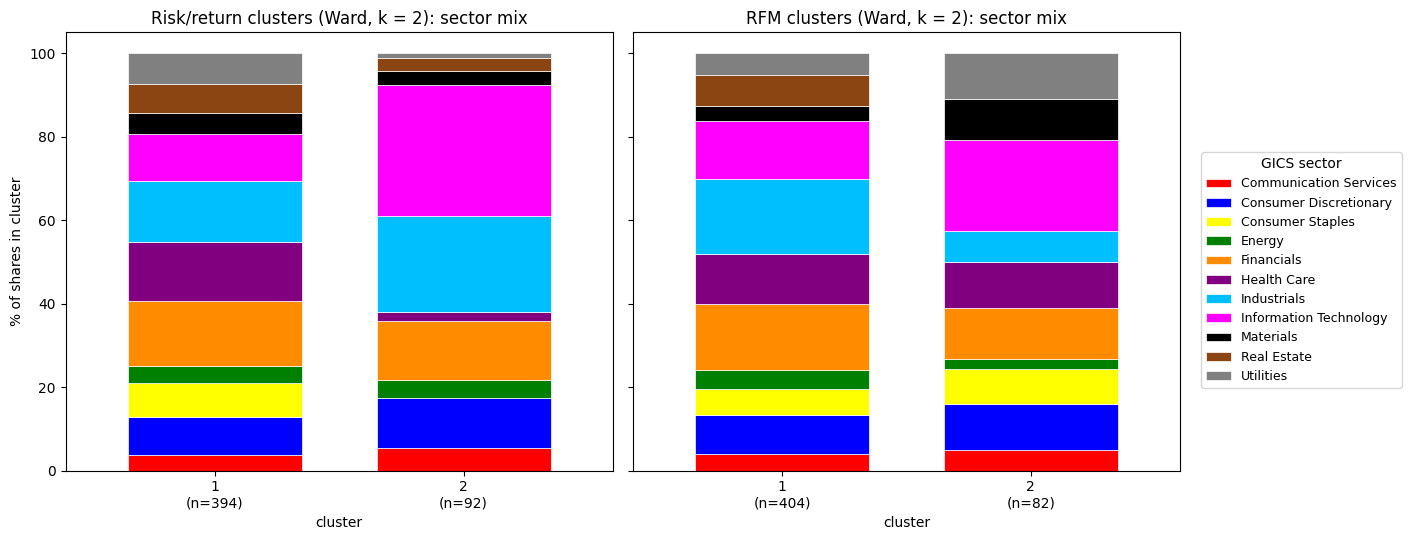

Sector share in each cluster minus sector share in the whole sample (percentage points)


ward_risk_return       ward_activity     
cluster                               1     2             1    2
GICS Sector                                                     
Communication Services             -0.3   1.3          -0.2  0.8
Consumer Discretionary             -0.5   2.3          -0.3  1.3
Consumer Staples                    1.5  -6.6          -0.4  2.0
Energy                             -0.1   0.2           0.3 -1.7
Financials                          0.3  -1.1           0.6 -3.0
Health Care                         2.3  -9.8           0.2 -1.0
Industrials                        -1.6   6.8           1.8 -8.7
Information Technology             -3.8  16.3          -1.4  6.7
Materials                           0.3  -1.5          -1.0  5.0
Real Estate                         0.7  -2.9           1.3 -6.2
Utilities                           1.2  -5.1          -1.0  4.8

In [36]:
# % of each cluster that comes from each sector (each column adds up to 100)
sector_pct = {name: pd.crosstab(model_data["GICS Sector"], assignments[name].rename("cluster"), normalize="columns") * 100
              for name in ["ward_risk_return", "ward_activity"]}
# sector mix of the whole sample, used as the comparison point
overall = model_data["GICS Sector"].value_counts(normalize=True) * 100

chart_titles = {"ward_risk_return": "Risk/return clusters", "ward_activity": "RFM clusters"}

# one fixed colour per sector: the primary colours (red, blue, yellow) first,
# then other strong plain colours, because there are 11 sectors to tell apart
sector_colours = {
    "Communication Services": "#FF0000",   # red
    "Consumer Discretionary": "#0000FF",   # blue
    "Consumer Staples": "#FFFF00",         # yellow
    "Energy": "#008000",                   # green
    "Financials": "#FF8C00",               # orange
    "Health Care": "#800080",              # purple
    "Industrials": "#00BFFF",              # light blue
    "Information Technology": "#FF00FF",   # magenta
    "Materials": "#000000",                # black
    "Real Estate": "#8B4513",              # brown
    "Utilities": "#808080",                # grey
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, (name, table) in zip(axes, sector_pct.items()):
    # each bar is one cluster, stacked by sector, adding up to 100%
    colours = [sector_colours.get(sector, "#D3D3D3") for sector in table.index]
    table.T.plot(kind="bar", stacked=True, ax=ax, width=0.7, color=colours,
                 edgecolor="white", linewidth=0.5, legend=False)

    # show the cluster size under each bar label
    sizes = assignments[name].value_counts().sort_index()
    ax.set_xticklabels([f"{c}\n(n={sizes[c]})" for c in table.columns], rotation=0)
    ax.set_title(f"{chart_titles[name]} (Ward, k = {chosen[name]}): sector mix")
    ax.set_xlabel("cluster")

axes[0].set_ylabel("% of shares in cluster")
# one shared legend for both charts, placed on the right
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="GICS sector", loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
fig.tight_layout()
save_fig(fig, "sector_composition")
plt.show()

# over or under representation compared with the whole sample (percentage points)
lift = pd.concat({name: table.sub(overall, axis=0) for name, table in sector_pct.items()}, axis=1)
print("Sector share in each cluster minus sector share in the whole sample (percentage points)")
display(lift.round(1))
pd.concat(sector_pct, axis=1).to_csv(OUT_DIR / "sector_composition_pct.csv")

In [37]:
# 3.2.3 limitations, with numbers
# do shares in the same risk-return cluster move together more than shares in different clusters?
corr_matrix = weekly_returns[model_data.index].corr().to_numpy()
labels = rr.to_numpy()
# same[i, j] is True when shares i and j are in the same cluster; the diagonal (a share with itself) is left out
same = labels[:, None] == labels[None, :]
off_diag = ~np.eye(len(labels), dtype=bool)

# lag-1 autocorrelation: does one week's return tell us anything about the next week's?
lag1 = weekly_returns[model_data.index].apply(lambda s: s.autocorr(lag=1))
# dividend effect: mean return from Adj Close minus mean return from Close, per year
close_weekly = close[model_data.index].resample("W-FRI").last()[complete_week].pct_change(fill_method=None).iloc[1:]
dividend_gap = (weekly_returns[model_data.index].mean() - close_weekly.mean()) * 52

# how concentrated traded value is in the 10 biggest shares
monetary_sorted = model_data["monetary"].sort_values(ascending=False)
# companies with two share classes (e.g. GOOG and GOOGL) share one CIK number on Wikipedia
in_sample = constituents[constituents["ticker"].isin(model_data.index)]
company_id = in_sample["CIK"] if "CIK" in in_sample else in_sample["Security"]
dual_class = company_id.duplicated(keep=False)

limits = pd.DataFrame({"value": {
    "Mean pairwise weekly return correlation, within risk-return clusters": corr_matrix[same & off_diag].mean(),
    "Mean pairwise weekly return correlation, between clusters": corr_matrix[~same].mean(),
    "Mean pairwise weekly return correlation, all pairs": corr_matrix[off_diag].mean(),
    "Median lag-1 autocorrelation of weekly returns": lag1.median(),
    "Median beta standard error": model_data["beta_se"].median(),
    "Median annual dividend effect (Adj Close vs Close mean return x 52)": dividend_gap.median(),
    "Kept shares added to the index after the start date": int(joined_late.sum()),
    "Share of total traded value in the top 10 shares": monetary_sorted.head(10).sum() / monetary_sorted.sum(),
    "Shares from companies with two share classes in the sample": int(dual_class.sum()),
}})
print("Evidence on the limitations")
display(limits)
limits.to_csv(OUT_DIR / "limitations_evidence.csv")

Evidence on the limitations


,value
"Mean pairwise weekly return correlation, within risk-return clusters",0.300876
"Mean pairwise weekly return correlation, between clusters",0.296445
"Mean pairwise weekly return correlation, all pairs",0.299513
Median lag-1 autocorrelation of weekly returns,-0.030357
Median beta standard error,0.100675
Median annual dividend effect (Adj Close vs Close mean return x 52),0.015256
Kept shares added to the index after the start date,72.000000
Share of total traded value in the top 10 shares,0.362907
Shares from companies with two share classes in the sample,6.000000


In [38]:
import zipfile

# save the versions, then zip the data snapshot and all outputs so nothing is lost when Colab closes
(OUT_DIR / "library_versions.json").write_text(json.dumps(versions, indent=2))
zip_name = "20230780_w2084700.zip"
files_to_zip = sorted(p for p in list(DATA_DIR.rglob("*")) + list(OUT_DIR.rglob("*")) if p.is_file())

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in files_to_zip:
        zf.write(path)
print(f"{len(files_to_zip)} files saved in {zip_name}")

# in Colab this downloads the zip to your computer; anywhere else it just stays in the folder
try:
    from google.colab import files
    files.download(zip_name)
except ImportError:
    print("Not running in Colab, the zip is in the working folder.")

38 files saved in 20230780_w2084700.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>